# ☕ Coffee Sales Analysis — Bộ 20 Biểu Đồ Khám Phá Dữ Liệu (EDA) Toàn Diện

> **Dự án:** Trực quan hóa dữ liệu bán hàng Coffee Sales (*Maven Roasters NYC*)  
> **Nhóm thực hiện:** **Tân Lưu (Leader)** • **Tân Lê** • **Quốc Thái** • **Ngọc Phước**  
> **Quy mô dữ liệu:** 149,116 giao dịch × 22 thuộc tính (01/01/2023 – 30/06/2023)  
> **Hướng dẫn cho nhóm:** Toàn bộ **20 biểu đồ phân tích chuyên sâu** dưới đây đã được chạy sẵn kết quả hiển thị trực tiếp ngay trong Notebook và lưu thành file ảnh `.png` độ phân giải cao tại thư mục `docs/charts/` để các thành viên lấy trực tiếp làm hình ảnh báo cáo & slide thuyết trình.

In [1]:
import sys
from pathlib import Path
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from IPython.display import Image, display

PROJECT_ROOT = Path.cwd().parent if Path.cwd().name == "notebook" else Path.cwd()
df = pd.read_csv(PROJECT_ROOT / "data" / "clean" / "coffee_sales_cleaned.csv")
print(f"Loaded Clean Dataset: {df.shape[0]:,} rows x {df.shape[1]} columns")
print(f"Total Revenue: ${df['revenue'].sum():,.2f} | Total Qty: {df['transaction_qty'].sum():,} | AOV: ${df['revenue'].mean():.2f}")

Loaded Clean Dataset: 149,116 rows x 22 columns
Total Revenue: $698,812.33 | Total Qty: 214,470 | AOV: $4.69


---
## PHẦN 1: KIỂM ĐỊNH DỮ LIỆU & PHÂN PHỐI BIẾN ĐỊNH LƯỢNG (PHÂN HỆ TÂN LÊ)
### Biểu đồ 1: Kiểm định độ toàn vẹn 11 cột gốc & Phân bố quy mô giỏ hàng (transaction_qty)
- **Nhận xét:** 100% dữ liệu trên cả 11 cột không có giá trị khuyết thiếu (0 Null). 97.78% đơn hàng mua từ 1 đến 2 sản phẩm.

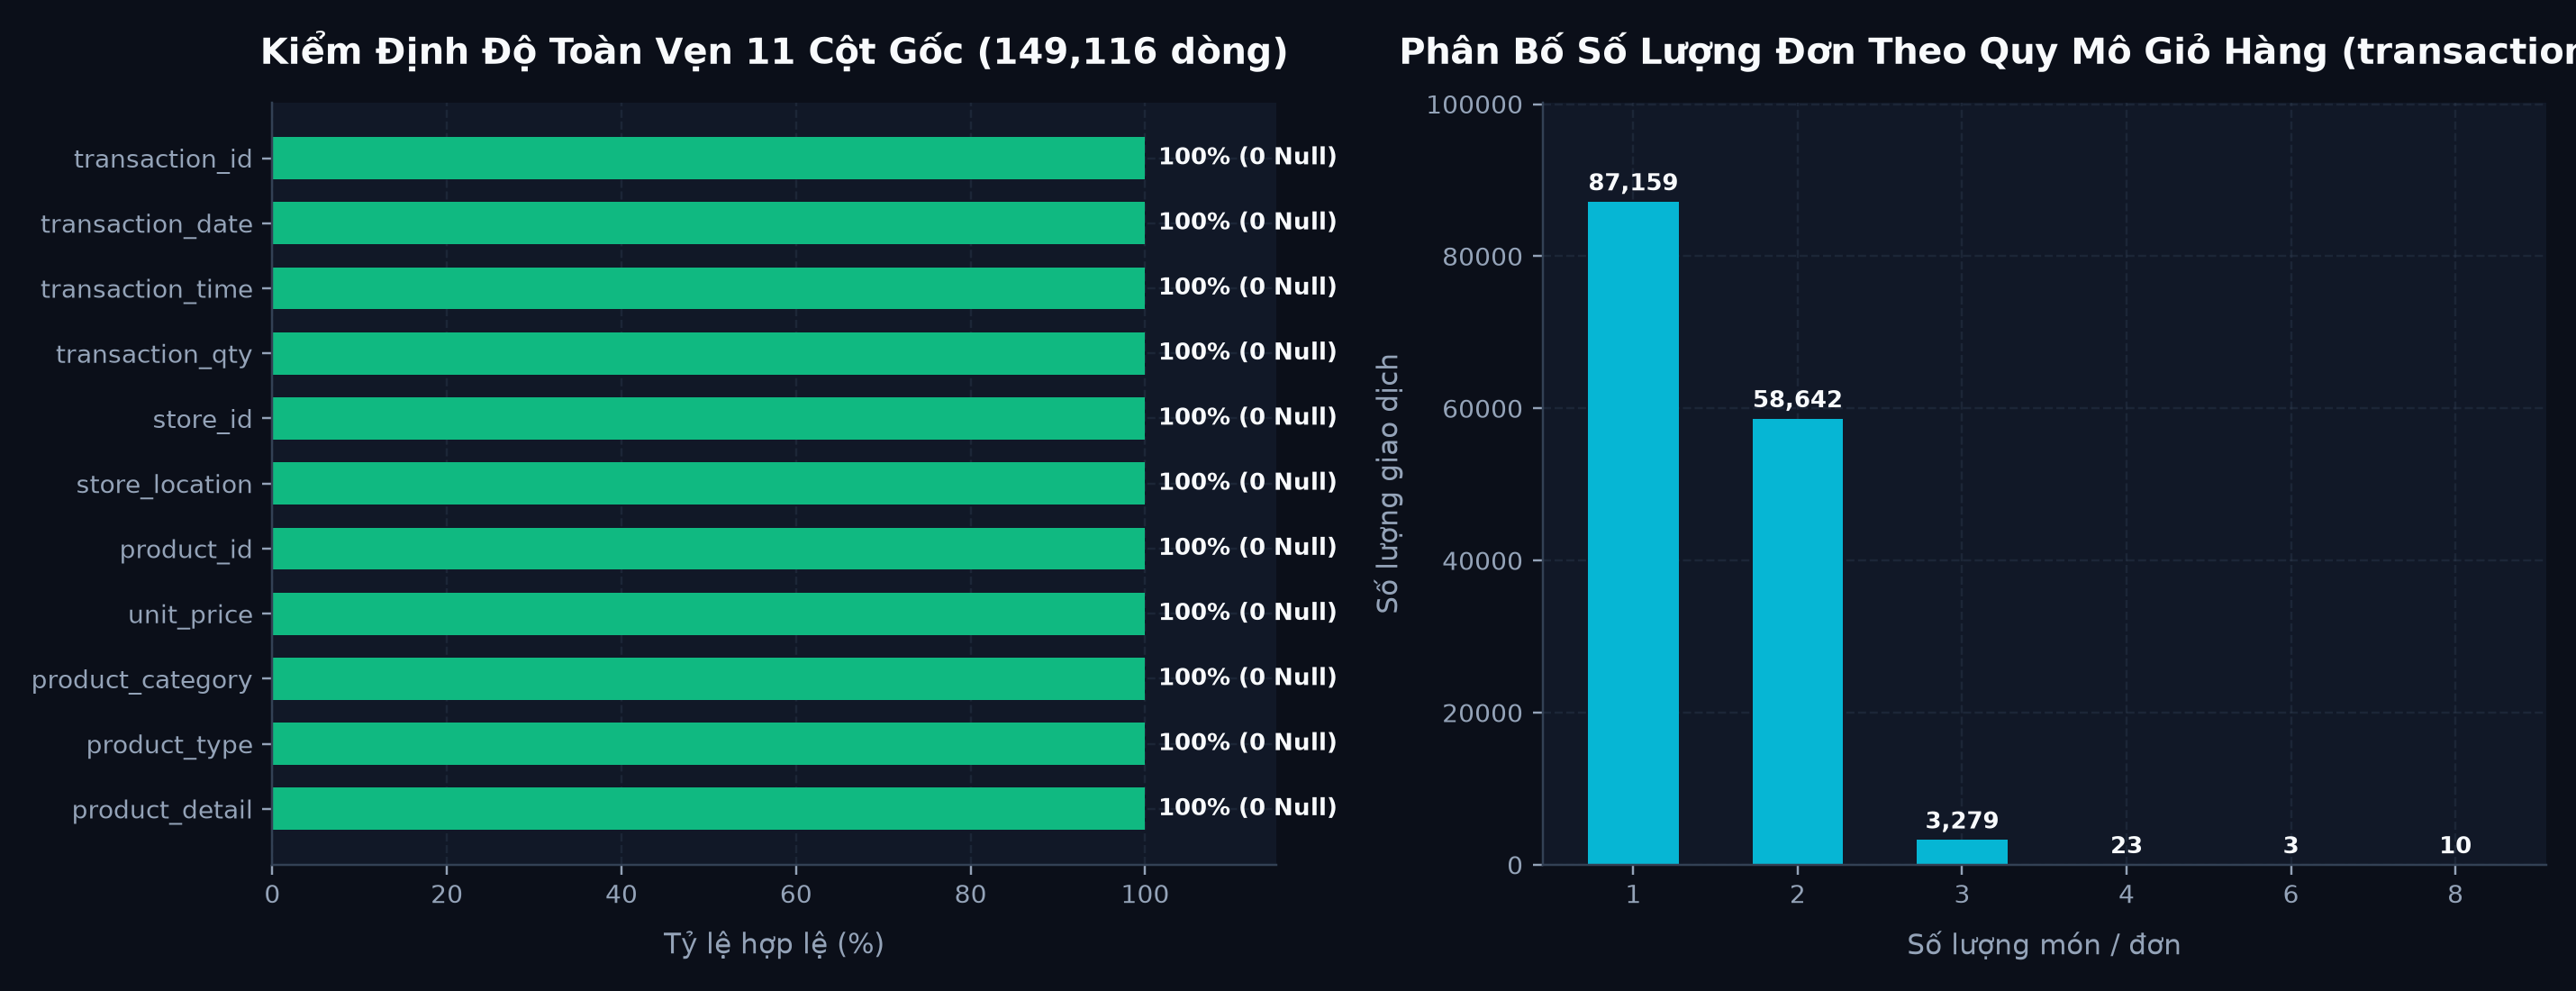

In [1]:
# Biểu đồ 1: Kiểm định độ toàn vẹn 11 cột gốc & Phân bố số lượng món mỗi đơn (docs/charts/slide07_data_audit.png)
display(Image(filename=str(PROJECT_ROOT / "docs" / "charts" / "slide07_data_audit.png")))

### Biểu đồ 2: Phân phối Đơn giá sản phẩm (unit_price) & Giá trị đơn hàng (revenue)
- **Nhận xét:** Đơn giá trung bình đạt $3.38/món (tập trung nhiều nhất ở mức $2.50 – $4.50). Giá trị trung bình mỗi đơn hàng (AOV) đạt $4.69.

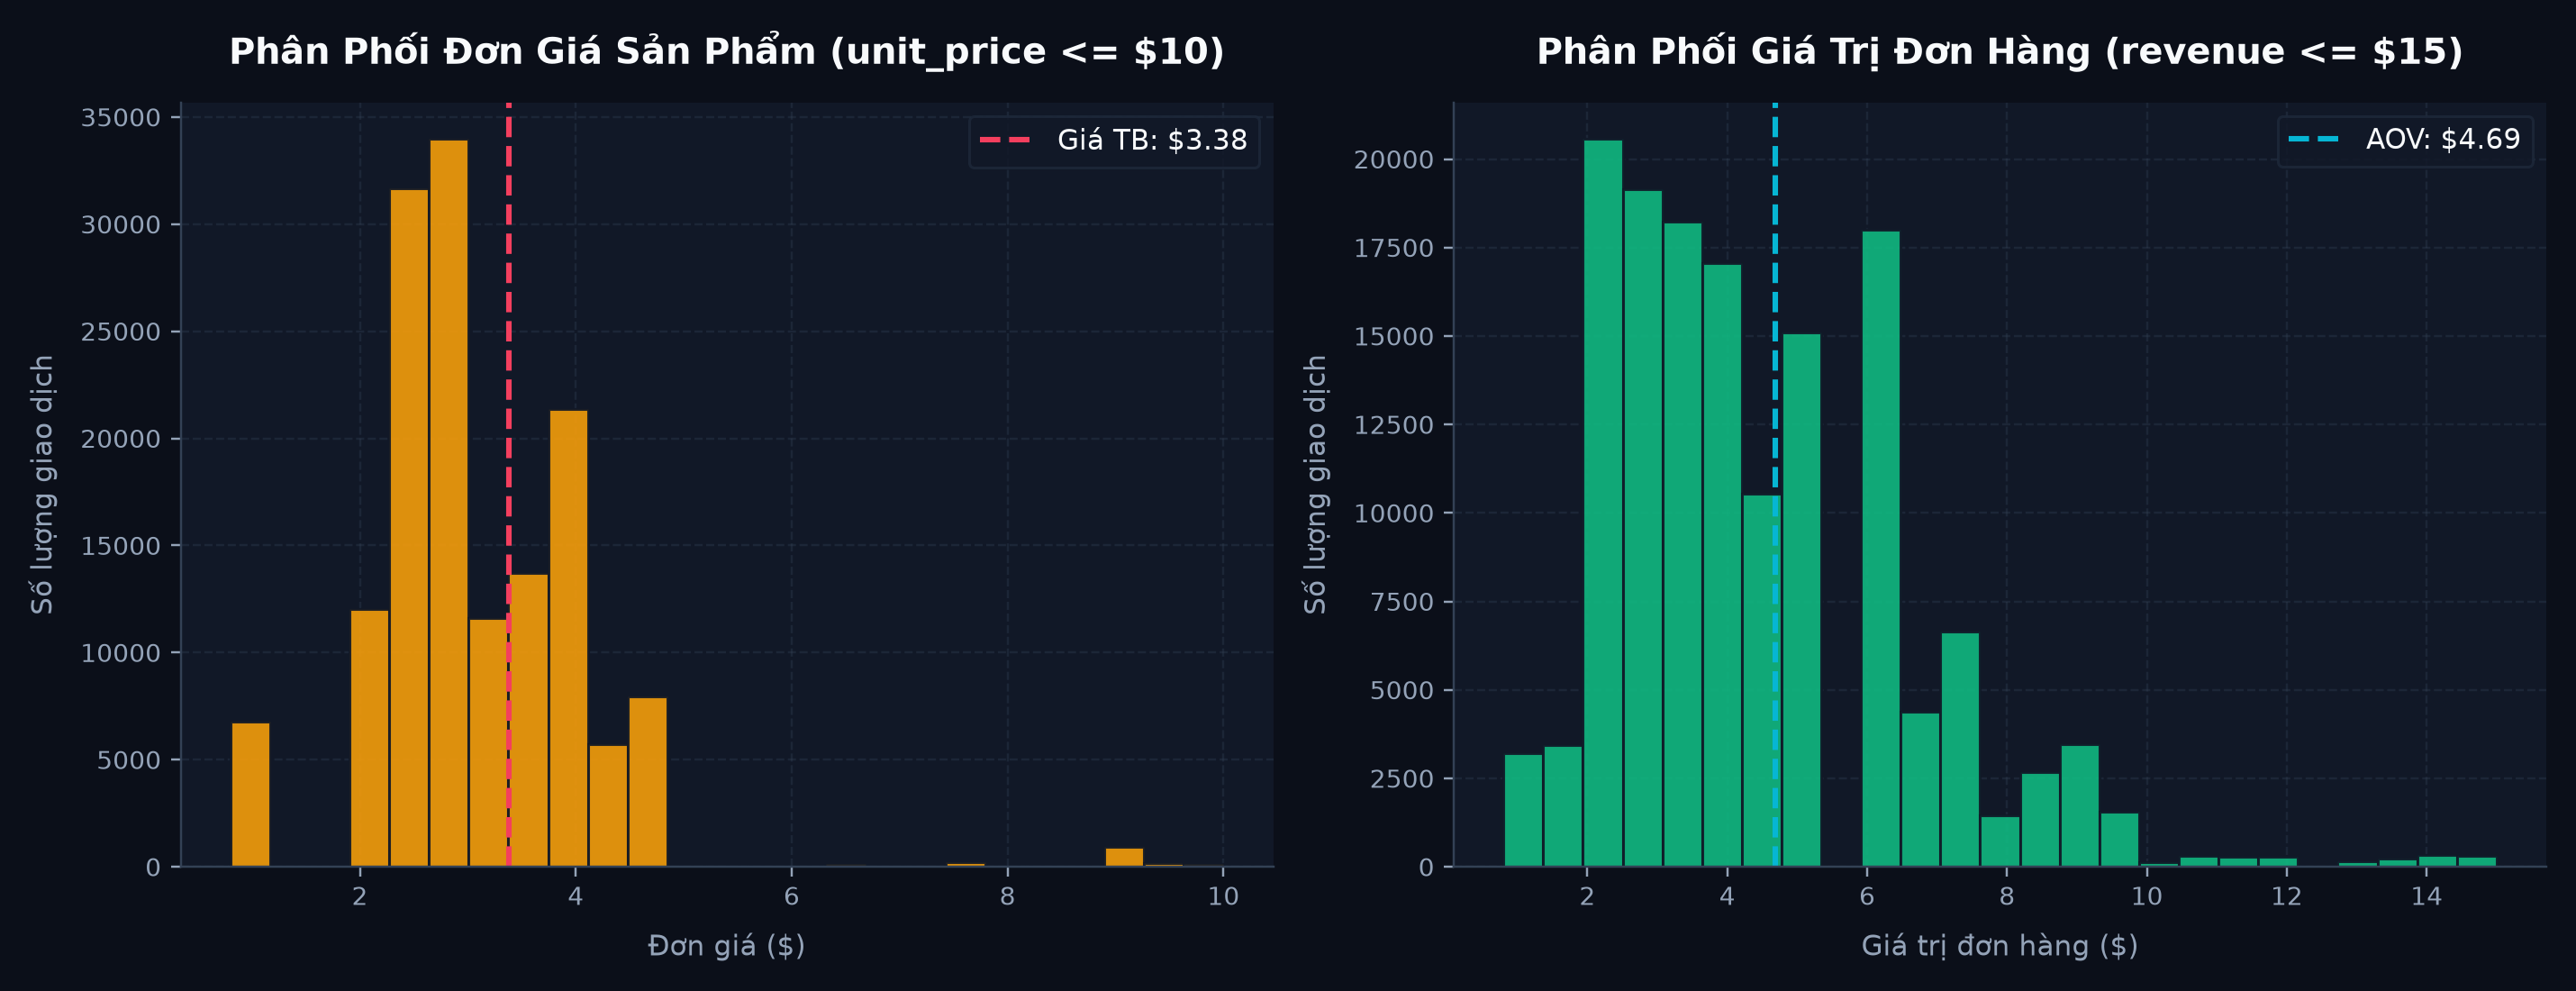

In [1]:
# Biểu đồ 2: Histogram phân phối Đơn giá & Giá trị đơn hàng (docs/charts/slide08_price_qty_dist.png)
display(Image(filename=str(PROJECT_ROOT / "docs" / "charts" / "slide08_price_qty_dist.png")))

### Biểu đồ 3: Boxplot & Violin Plot phân phối Giá trị đơn hàng và Đơn giá giữa 3 Chi nhánh
- **Nhận xét:** Phân phối đơn giá giữa 3 chi nhánh đồng nhất, nhưng Lower Manhattan có khoảng tứ phân vị (IQR) của giá trị đơn hàng rộng hơn nhờ quy mô giỏ hàng lớn (1.50 món/đơn).

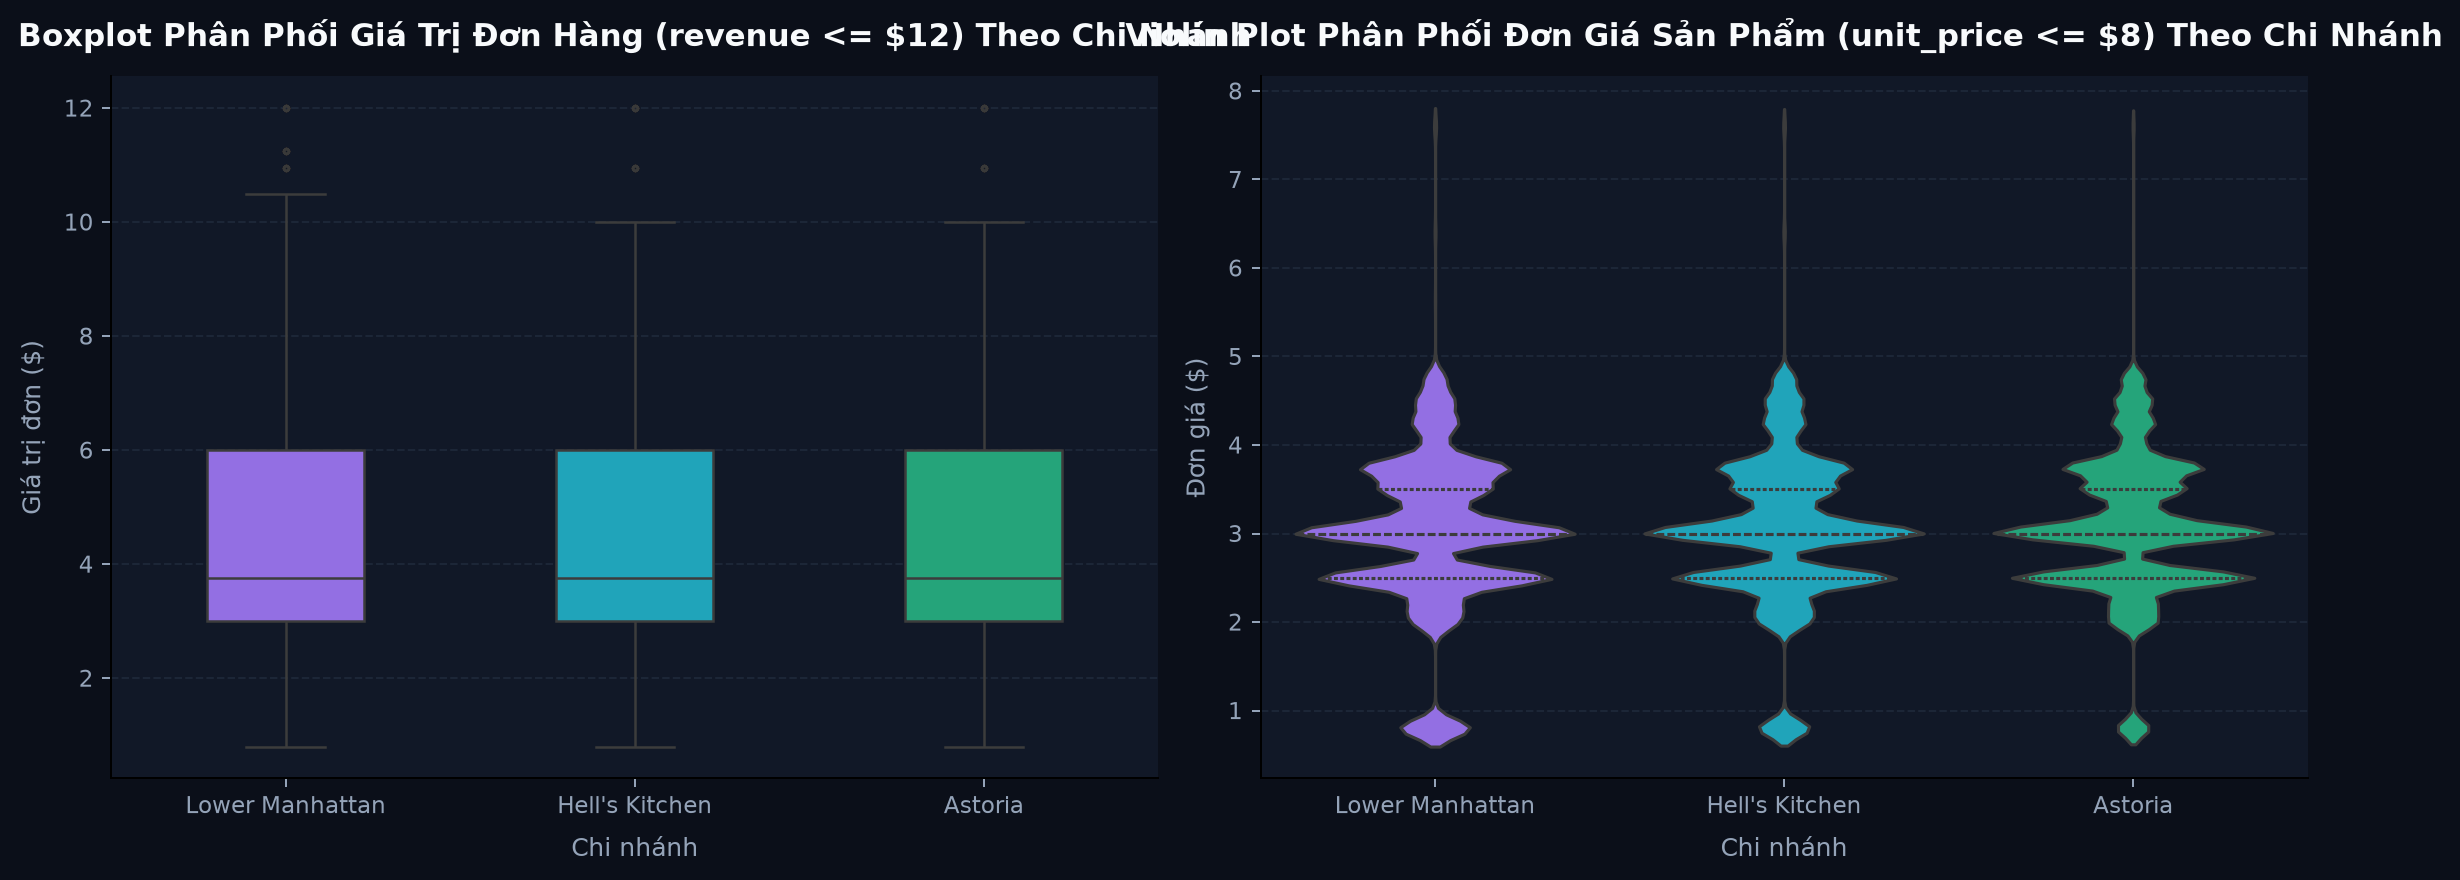

In [1]:
# Biểu đồ 3: Boxplot & Violin Plot so sánh phân phối giữa 3 chi nhánh (docs/charts/nb_chart03_store_boxplot_violin.png)
display(Image(filename=str(PROJECT_ROOT / "docs" / "charts" / "nb_chart03_store_boxplot_violin.png")))

---
## PHẦN 2: SO SÁNH HIỆU SUẤT 3 CHI NHÁNH TẠI NEW YORK (PHÂN HỆ TÂN LƯU)
### Biểu đồ 4: So sánh Tổng Doanh Thu, Số Đơn Hàng & Giá Trị Đơn Trung Bình (AOV) giữa 3 Chi Nhánh
- **Nhận xét:** Hell's Kitchen dẫn đầu tổng doanh thu ($236,511.17 - 33.84%), Astoria đứng thứ 2 ($232,243.91 - 33.23%), Lower Manhattan đứng thứ 3 ($230,057.25 - 32.92%) nhưng dẫn đầu về AOV ($4.81/đơn).

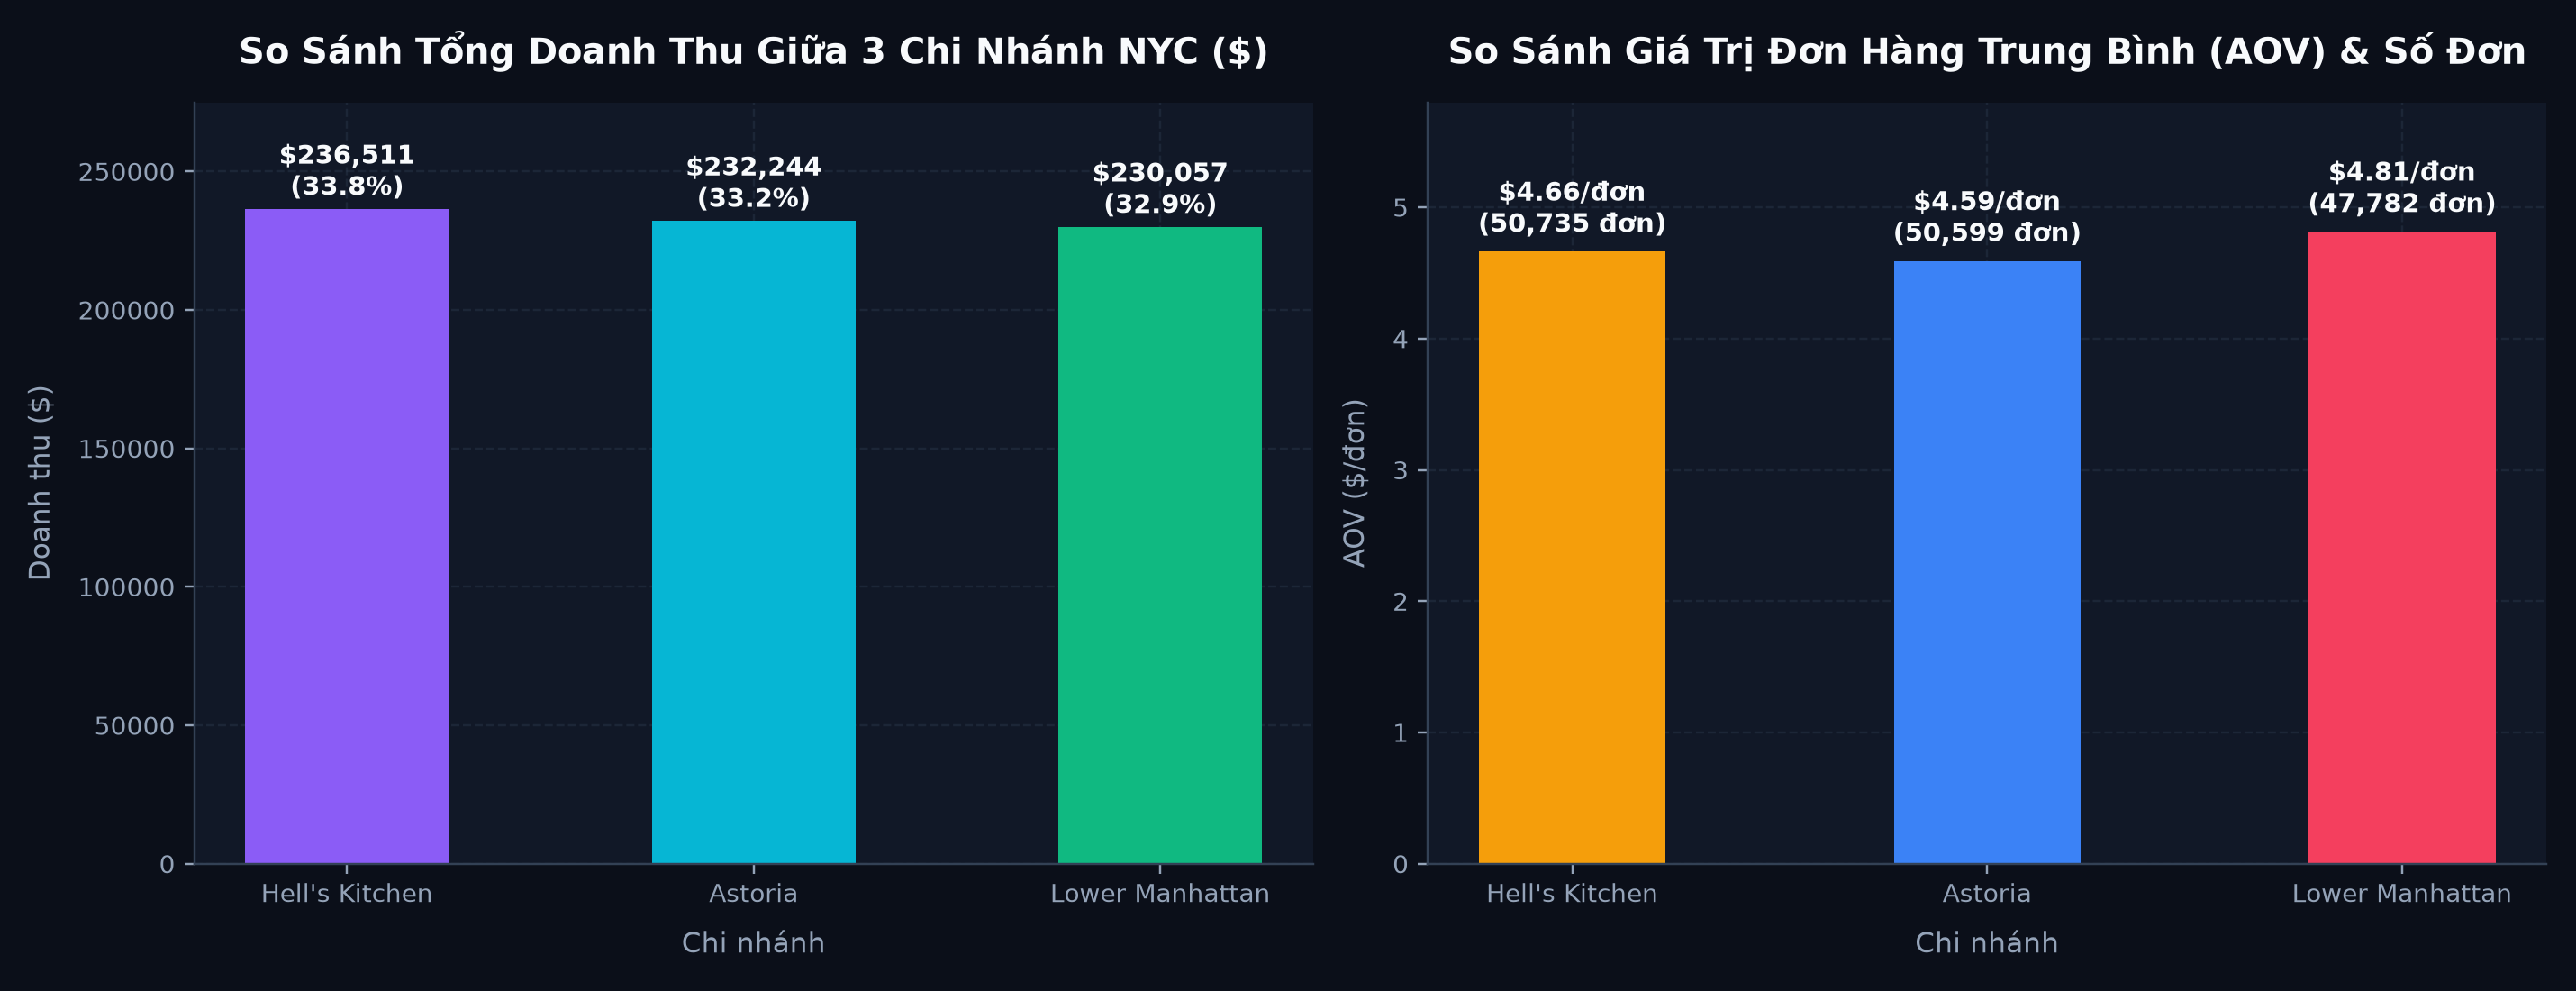

In [1]:
# Biểu đồ 4: So sánh Doanh thu & AOV 3 chi nhánh (docs/charts/slide12_store_comparison.png)
display(Image(filename=str(PROJECT_ROOT / "docs" / "charts" / "slide12_store_comparison.png")))

### Biểu đồ 5: Đối chiếu Tốc độ Tăng trưởng Doanh thu 6 Tháng của Từng Chi nhánh
- **Nhận xét:** Cả 3 chi nhánh đều tăng trưởng song hành gấp hơn 2 lần từ Tháng 1 đến Tháng 6/2023.

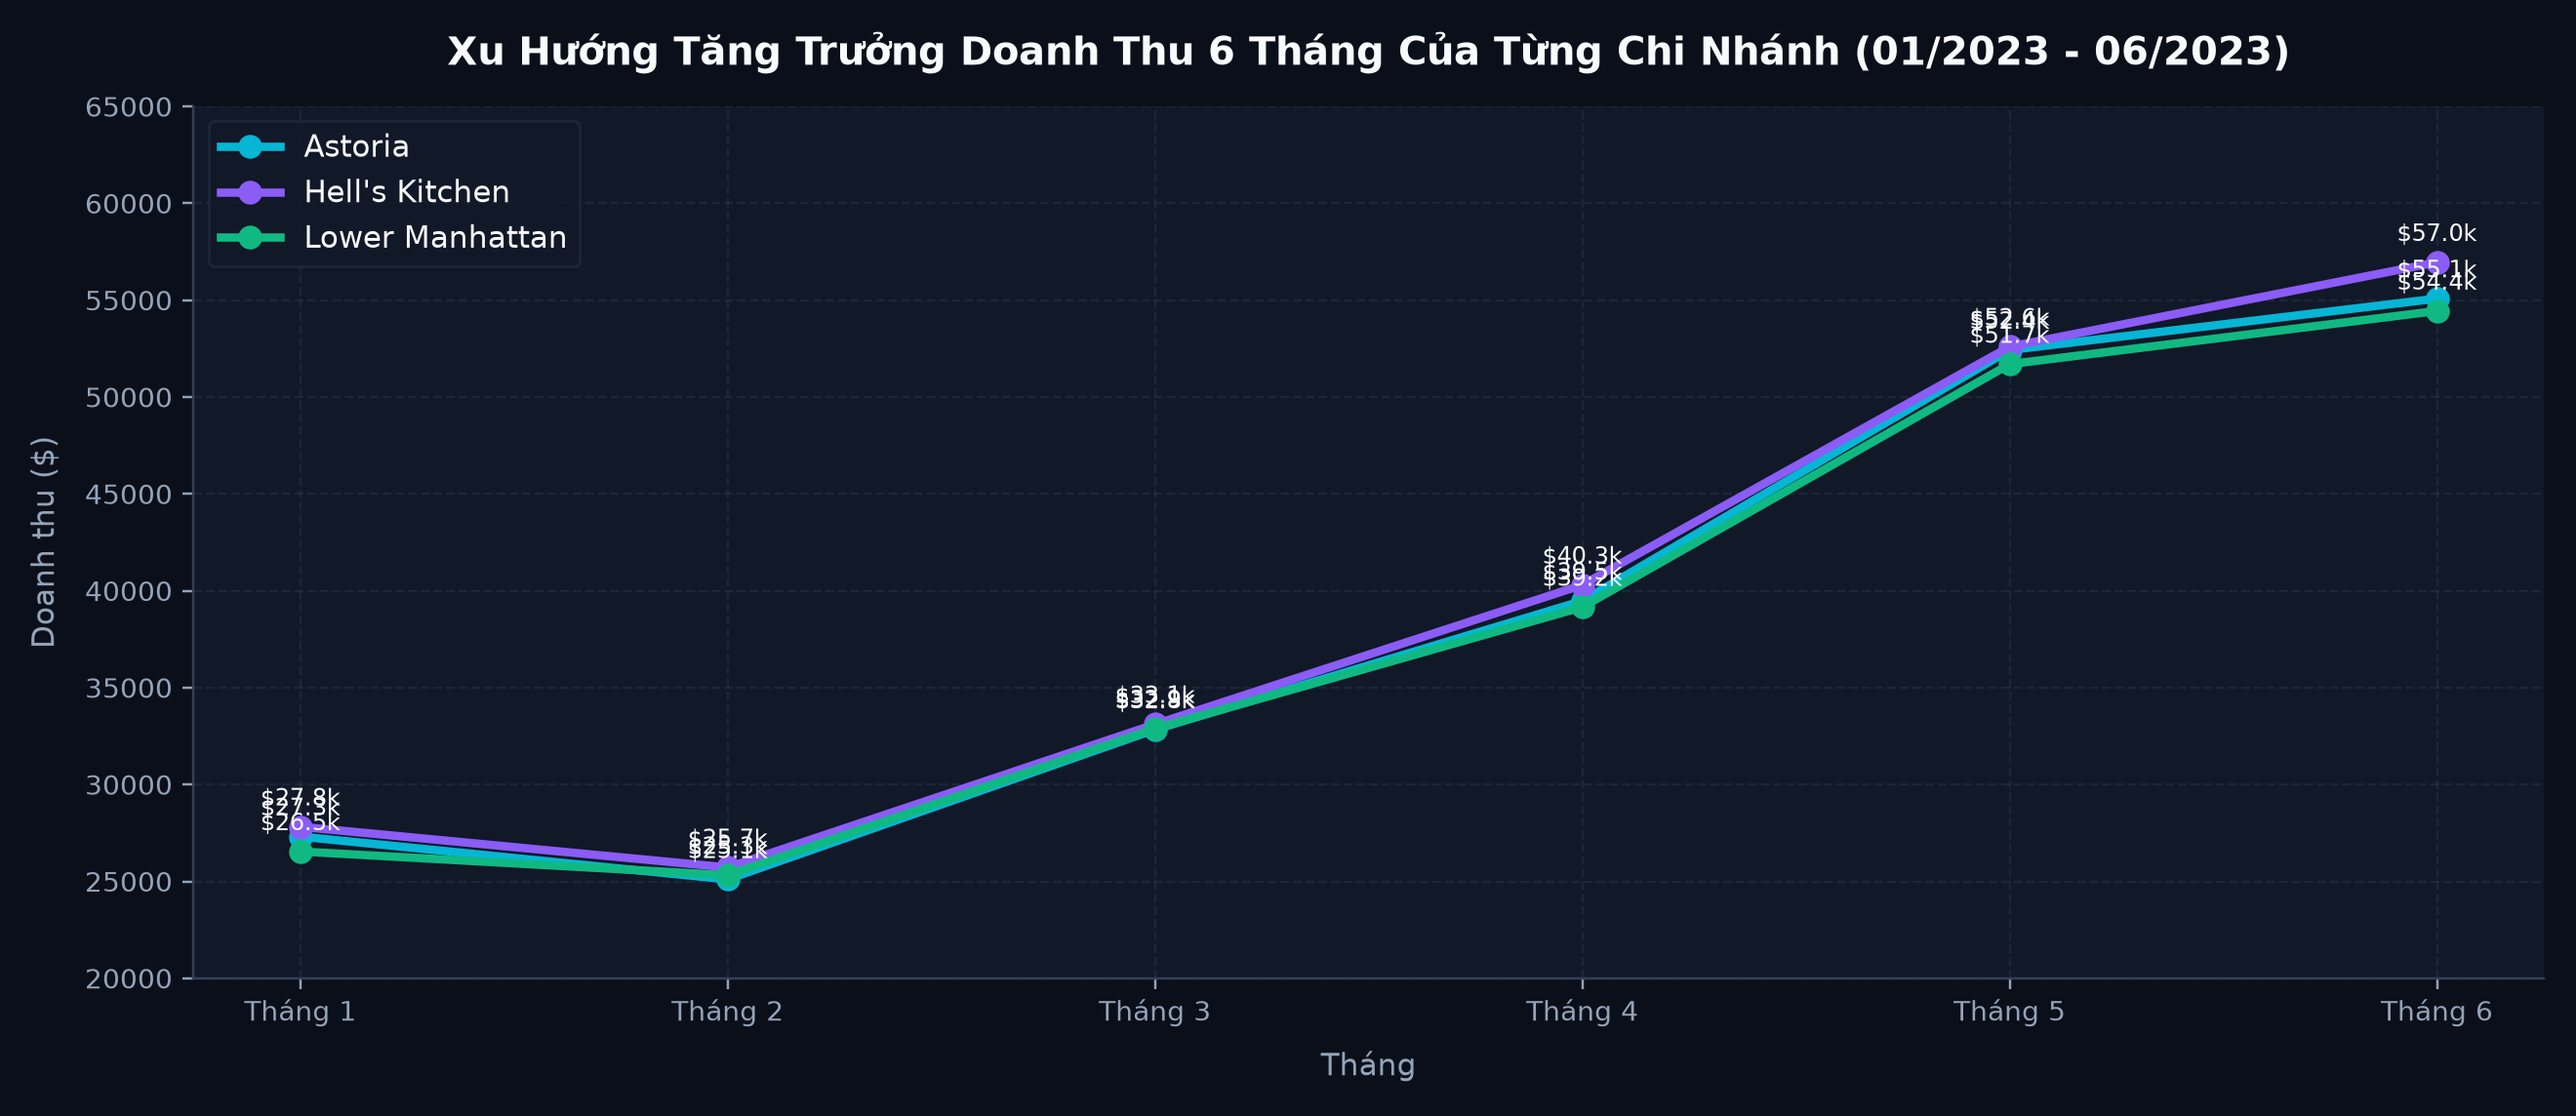

In [1]:
# Biểu đồ 5: Đà tăng trưởng 6 tháng của 3 chi nhánh (docs/charts/slide13_store_monthly_trend.png)
display(Image(filename=str(PROJECT_ROOT / "docs" / "charts" / "slide13_store_monthly_trend.png")))

---
## PHẦN 3: PHÂN TÍCH CHUỖI THỜI GIAN — "THỜI ĐIỂM NÀO BÁN CHẠY?" (PHÂN HỆ QUỐC THÁI)
### Biểu đồ 6: Xu hướng Tăng trưởng Doanh thu 6 Tháng Đầu Năm 2023 (+103.8%)
- **Nhận xét:** Doanh thu toàn chuỗi bứt phá từ $81,678 (Tháng 1) lên đỉnh $166,486 (Tháng 6), tương ứng tốc độ tăng trưởng +103.8%.

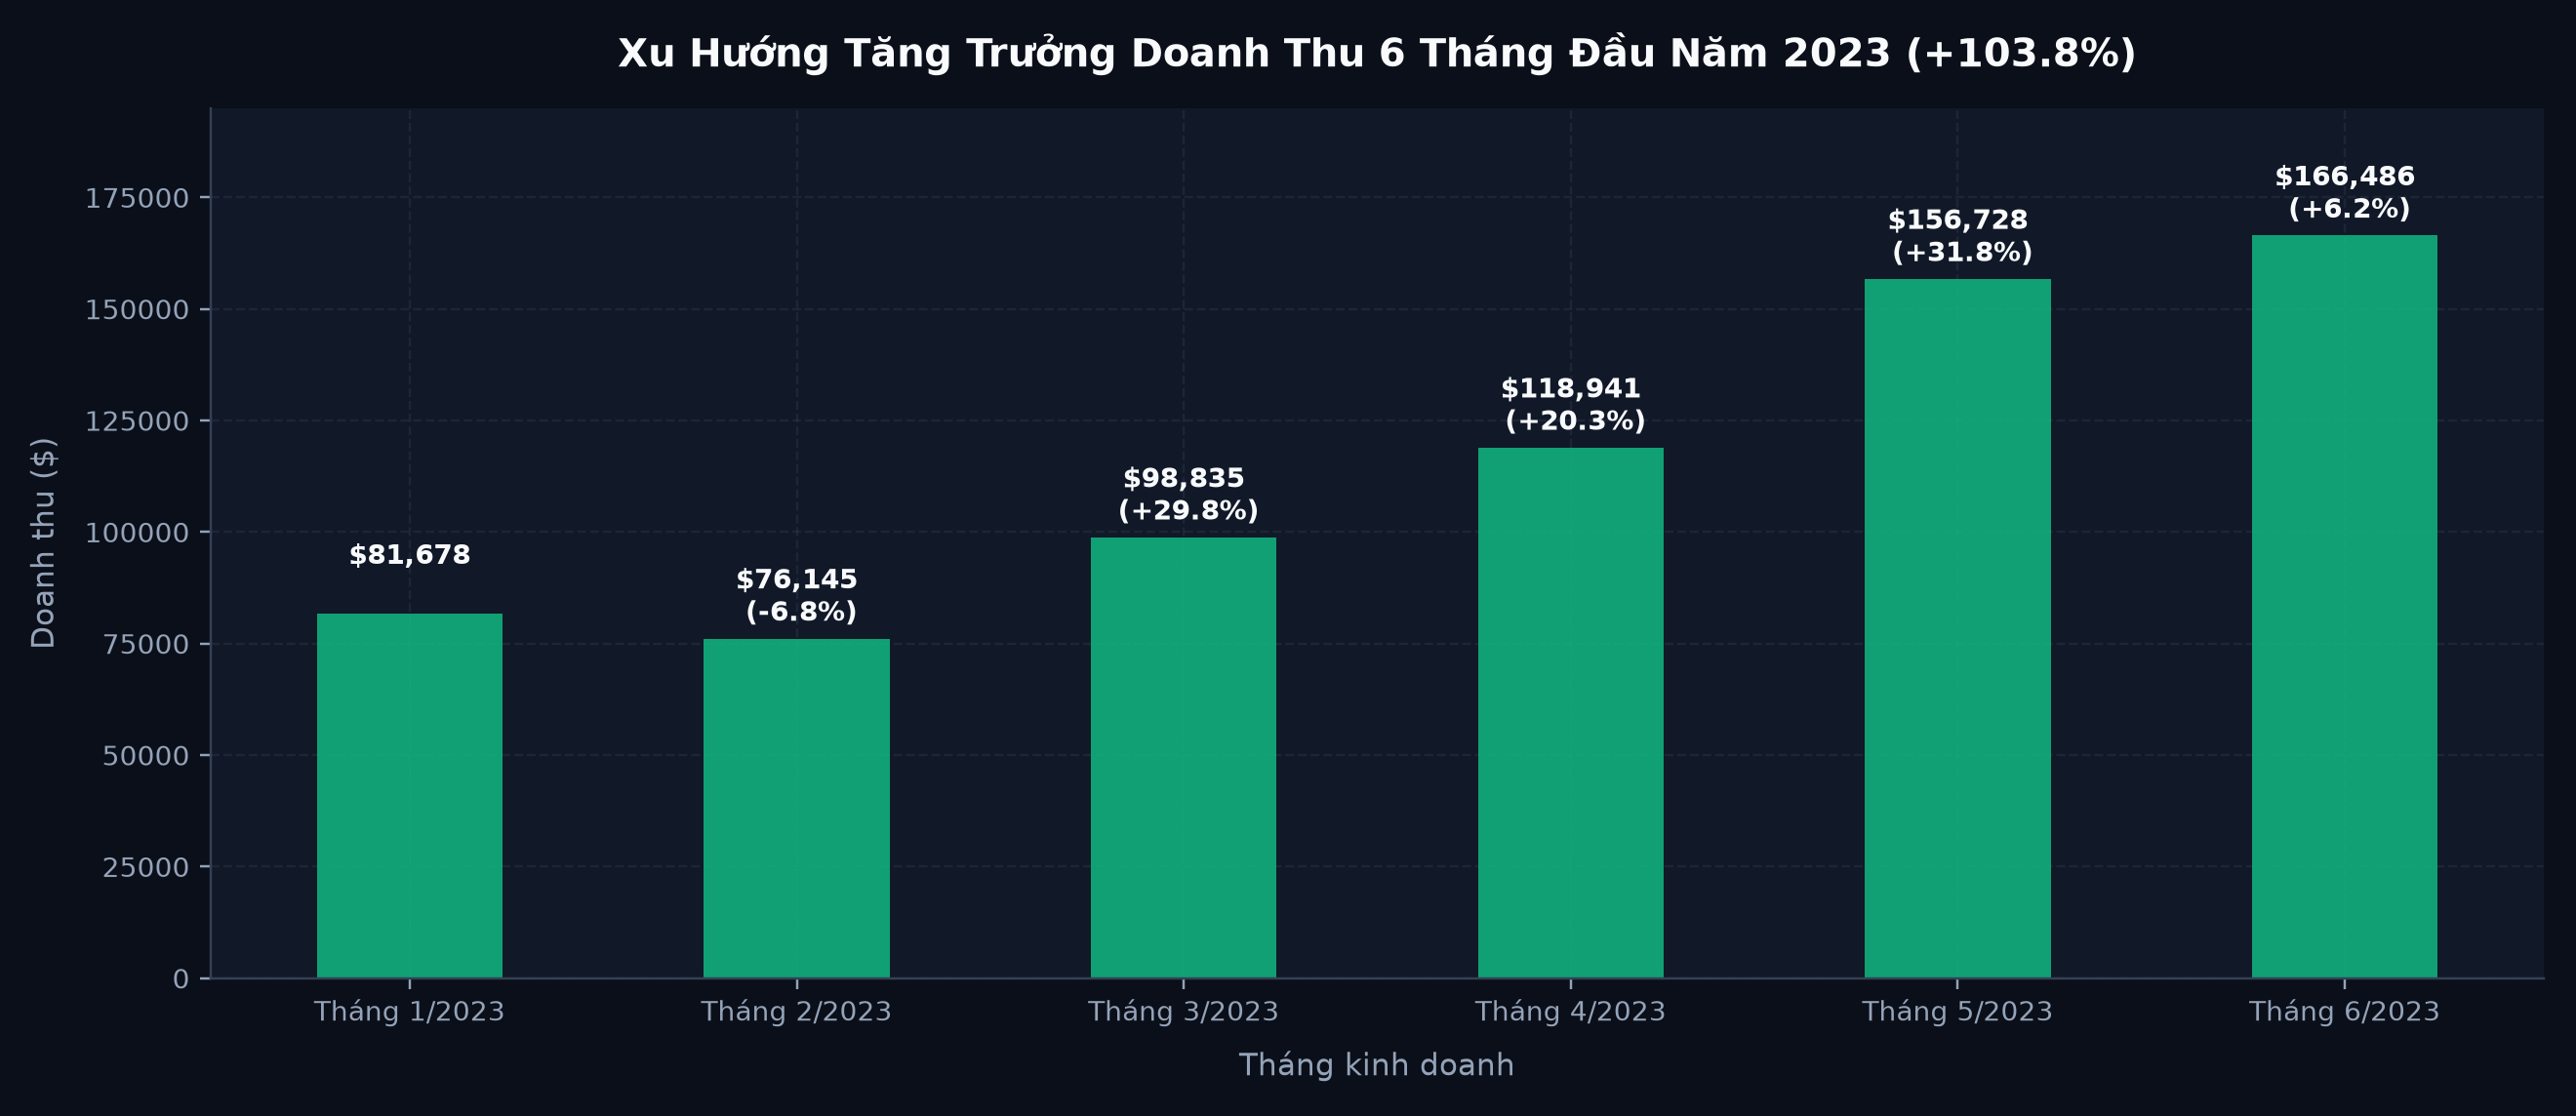

In [1]:
# Biểu đồ 6: Doanh thu theo tháng & Tốc độ tăng trưởng MoM (docs/charts/slide14_monthly_revenue_trend.png)
display(Image(filename=str(PROJECT_ROOT / "docs" / "charts" / "slide14_monthly_revenue_trend.png")))

### Biểu đồ 7: Chuỗi thời gian Doanh thu 181 Ngày Liên tục & Đường Trung bình Trượt 7 Ngày (MA7)
- **Nhận xét:** Đường MA7 làm rõ xu hướng tăng trưởng bậc thang qua từng tháng từ ~$2,600/ngày lên ~$5,550/ngày.

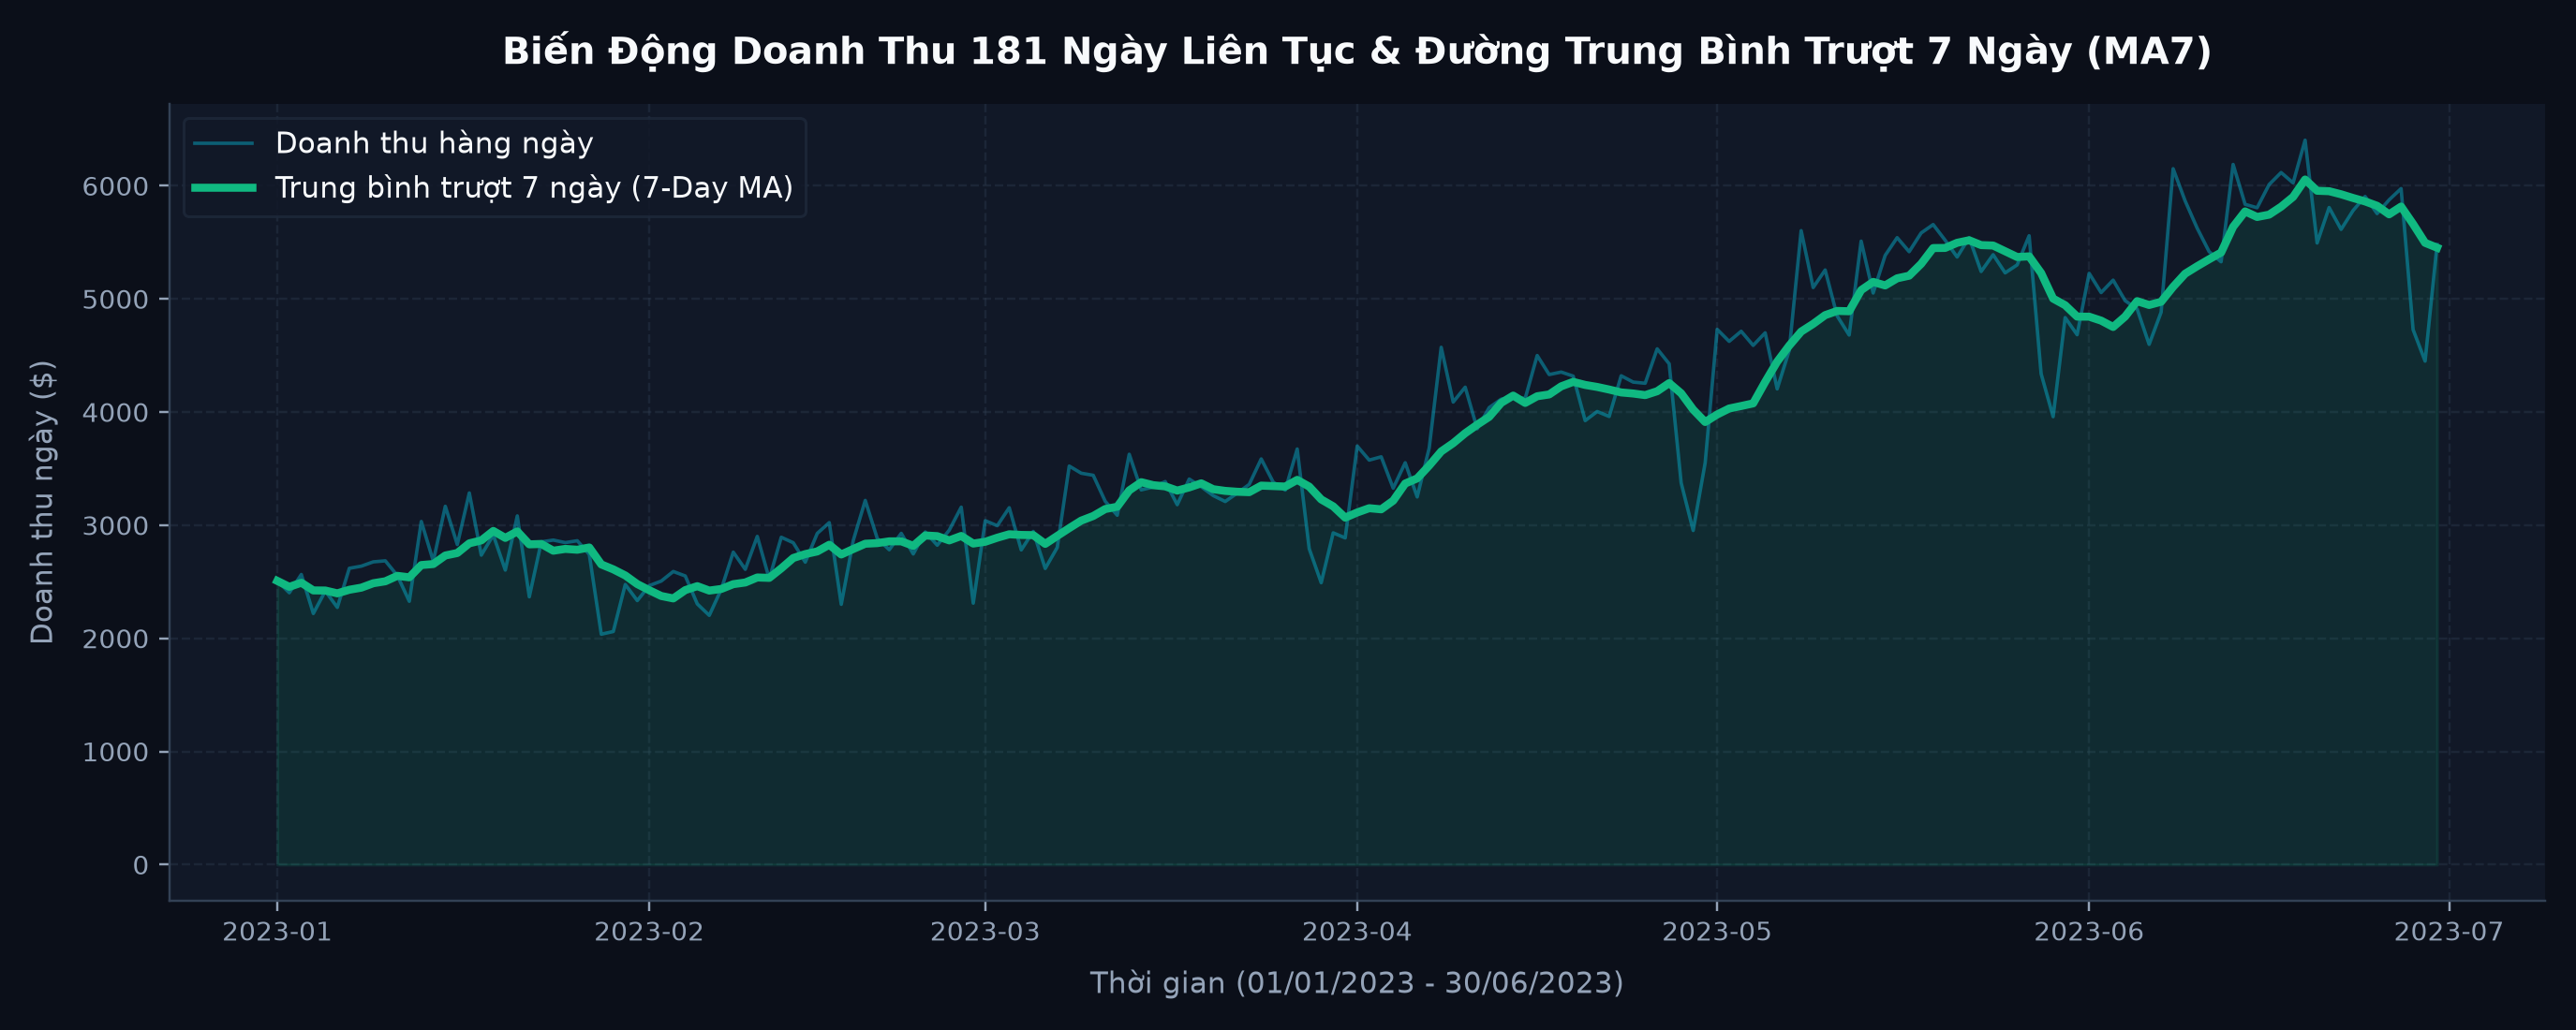

In [1]:
# Biểu đồ 7: Time-series 181 ngày & 7-Day Moving Average (docs/charts/slide15_daily_sales_series.png)
display(Image(filename=str(PROJECT_ROOT / "docs" / "charts" / "slide15_daily_sales_series.png")))

### Biểu đồ 8: Phân phối Doanh thu & Sản lượng theo 15 Khung Giờ Mở Cửa (06:00 – 20:59)
- **Nhận xét:** Khung giờ vàng 07:00 – 10:59 sáng tạo ra $320,069.26 (45.80% doanh thu cả ngày). Đỉnh cao nhất là 10:00 sáng ($88,673.39).

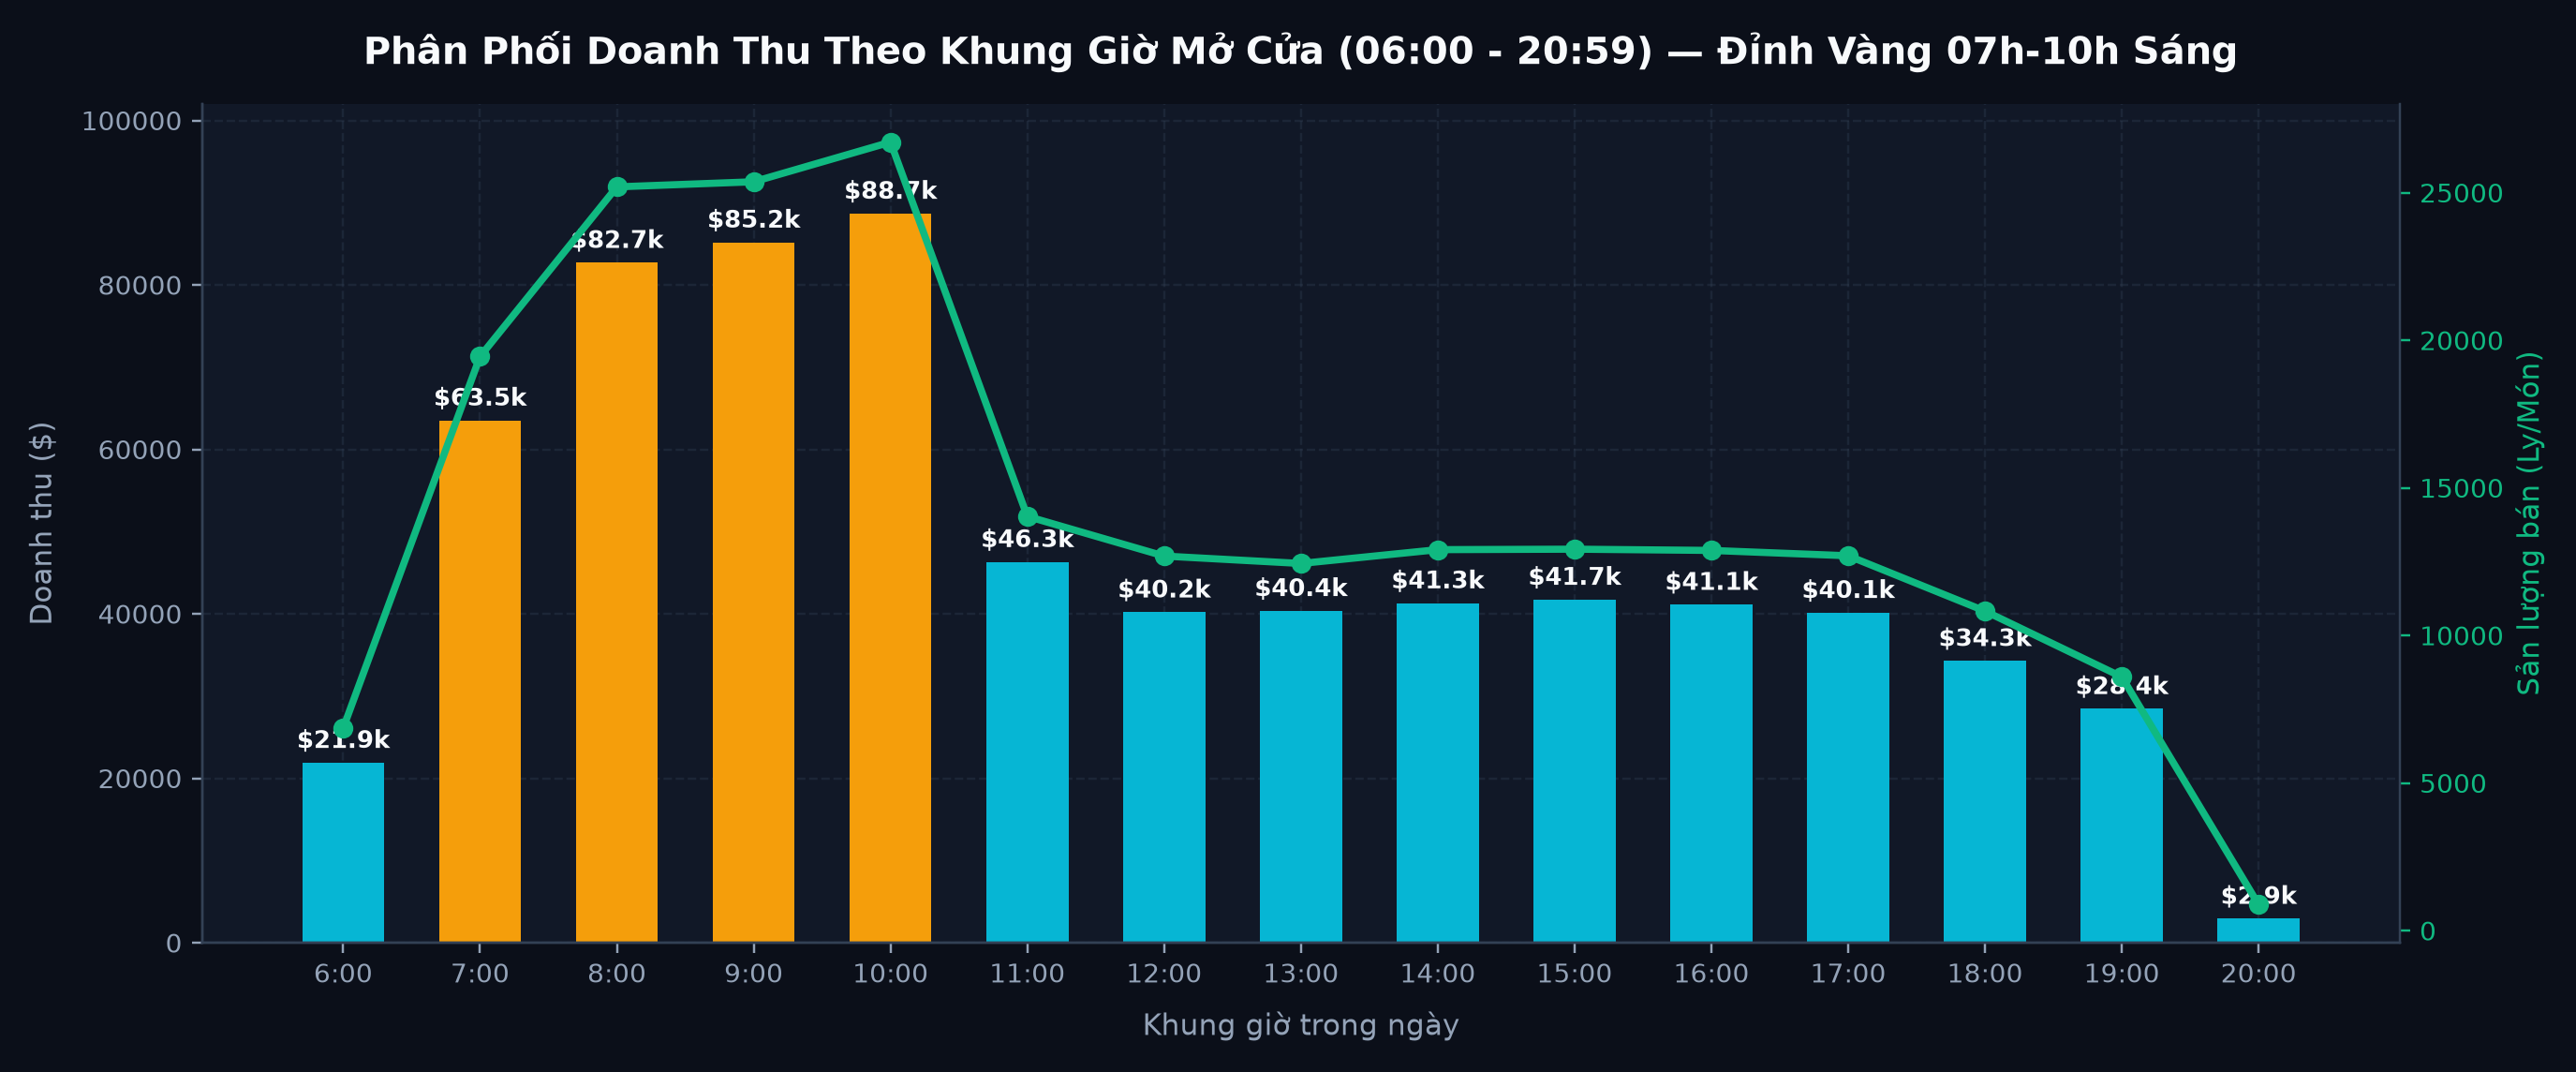

In [1]:
# Biểu đồ 8: Đỉnh cao điểm sáng 07h-10h chiếm 45.80% tổng doanh thu (docs/charts/slide16_hourly_peak_sales.png)
display(Image(filename=str(PROJECT_ROOT / "docs" / "charts" / "slide16_hourly_peak_sales.png")))

### Biểu đồ 9: Cơ cấu Doanh thu & Tỷ trọng theo 4 Ca Kinh doanh trong ngày
- **Nhận xét:** Ca Sáng (06h–10h) chiếm 48.9%, Ca Chiều (14h–17h) chiếm 23.5%, Ca Trưa (11h–13h) chiếm 18.2%, và Ca Tối (18h–21h) chỉ chiếm 9.4%.

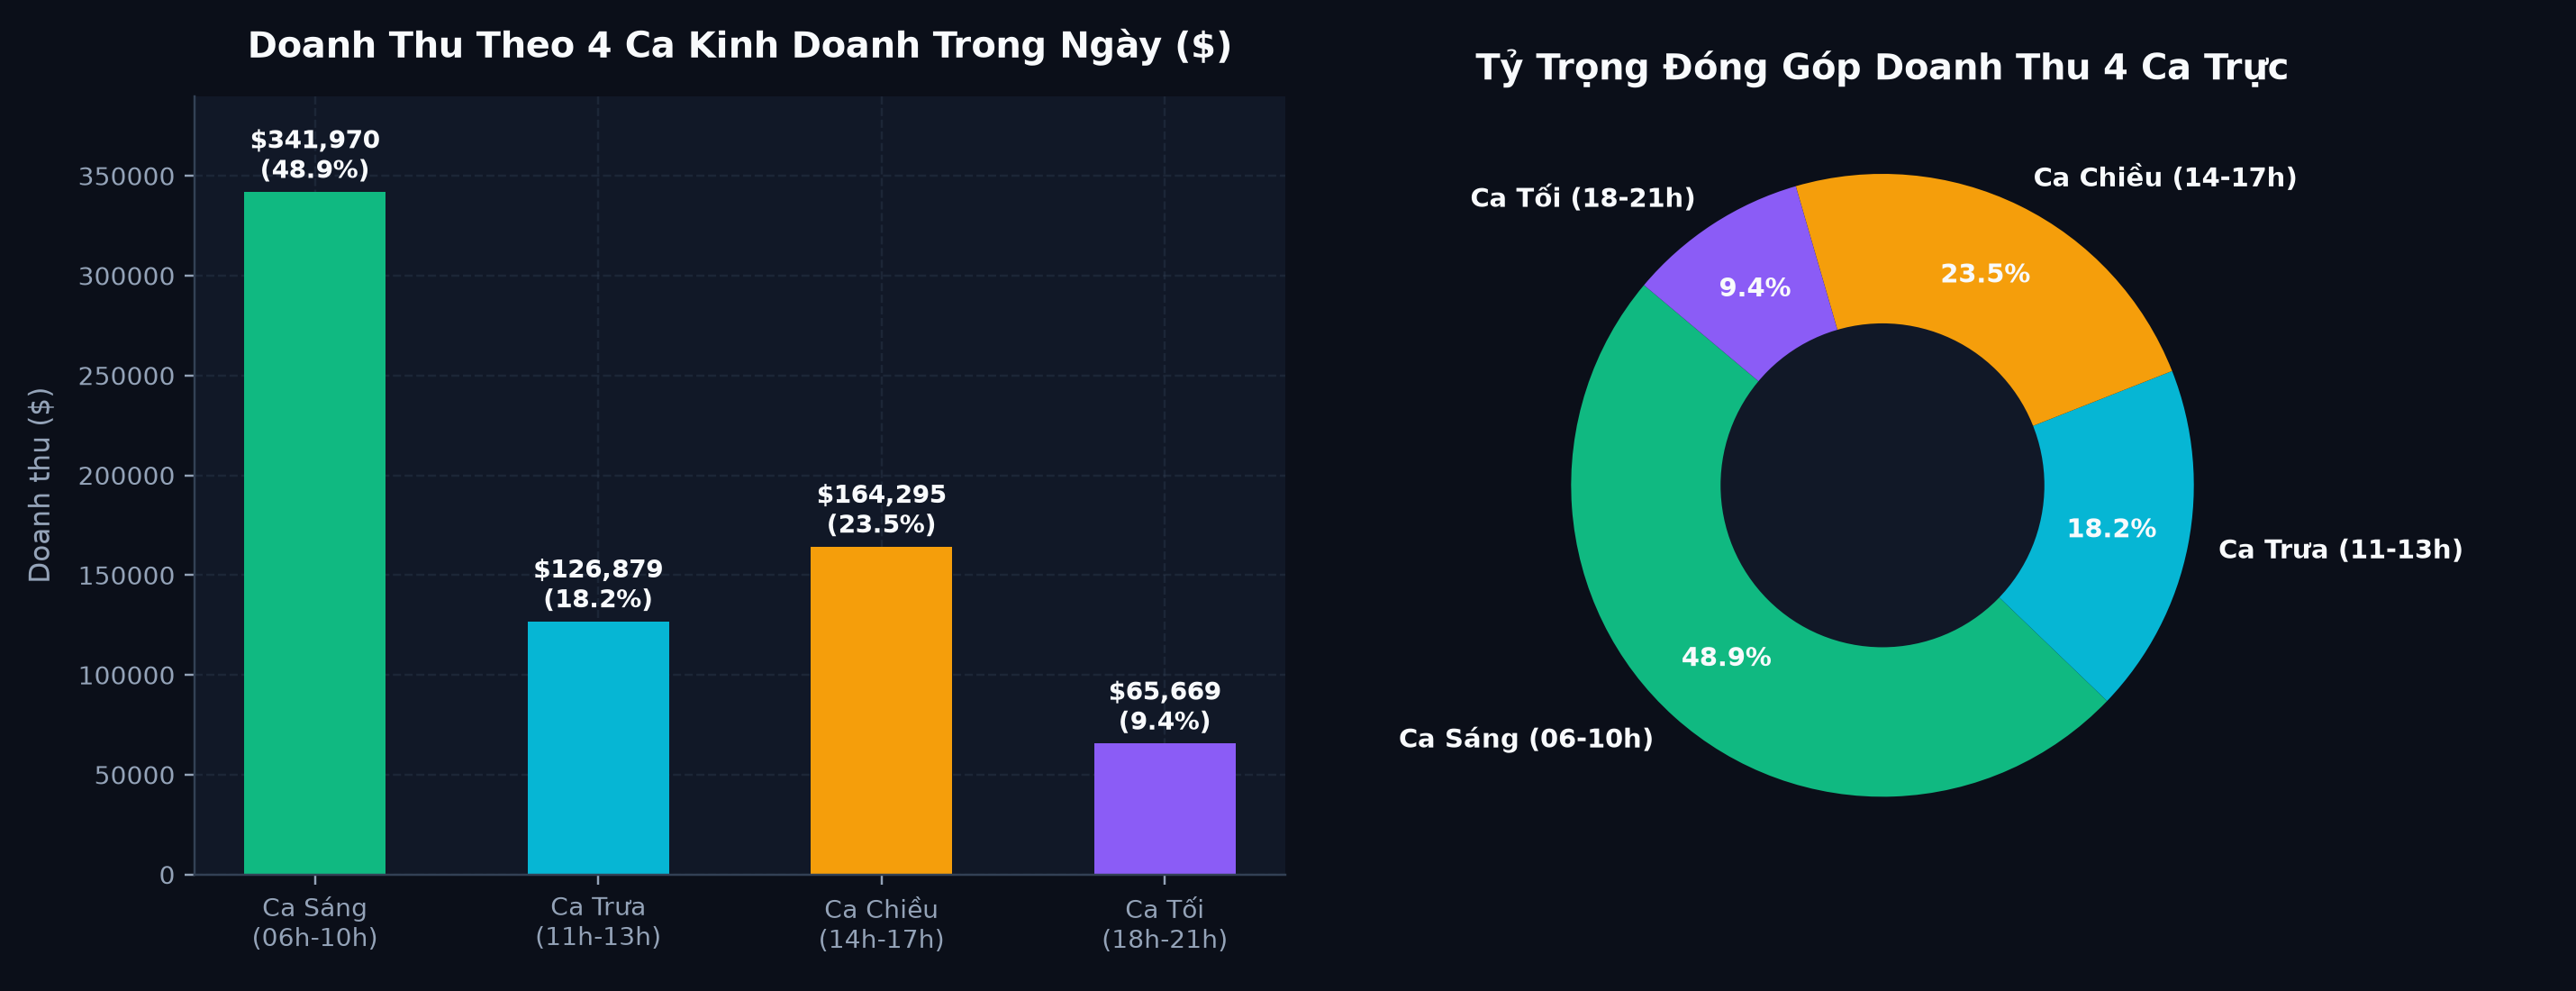

In [1]:
# Biểu đồ 9: So sánh 4 ca trực Ca Sáng / Ca Trưa / Ca Chiều / Ca Tối (docs/charts/slide17_time_slot_breakdown.png)
display(Image(filename=str(PROJECT_ROOT / "docs" / "charts" / "slide17_time_slot_breakdown.png")))

### Biểu đồ 10: So sánh Doanh thu theo 7 Thứ trong tuần (Thứ 2 – Chủ Nhật)
- **Nhận xét:** Thứ Hai ($101,677.28) và Thứ Sáu ($101,373.00) dẫn đầu tuần; Thứ Bảy ($96,894.48) thấp nhất tuần.

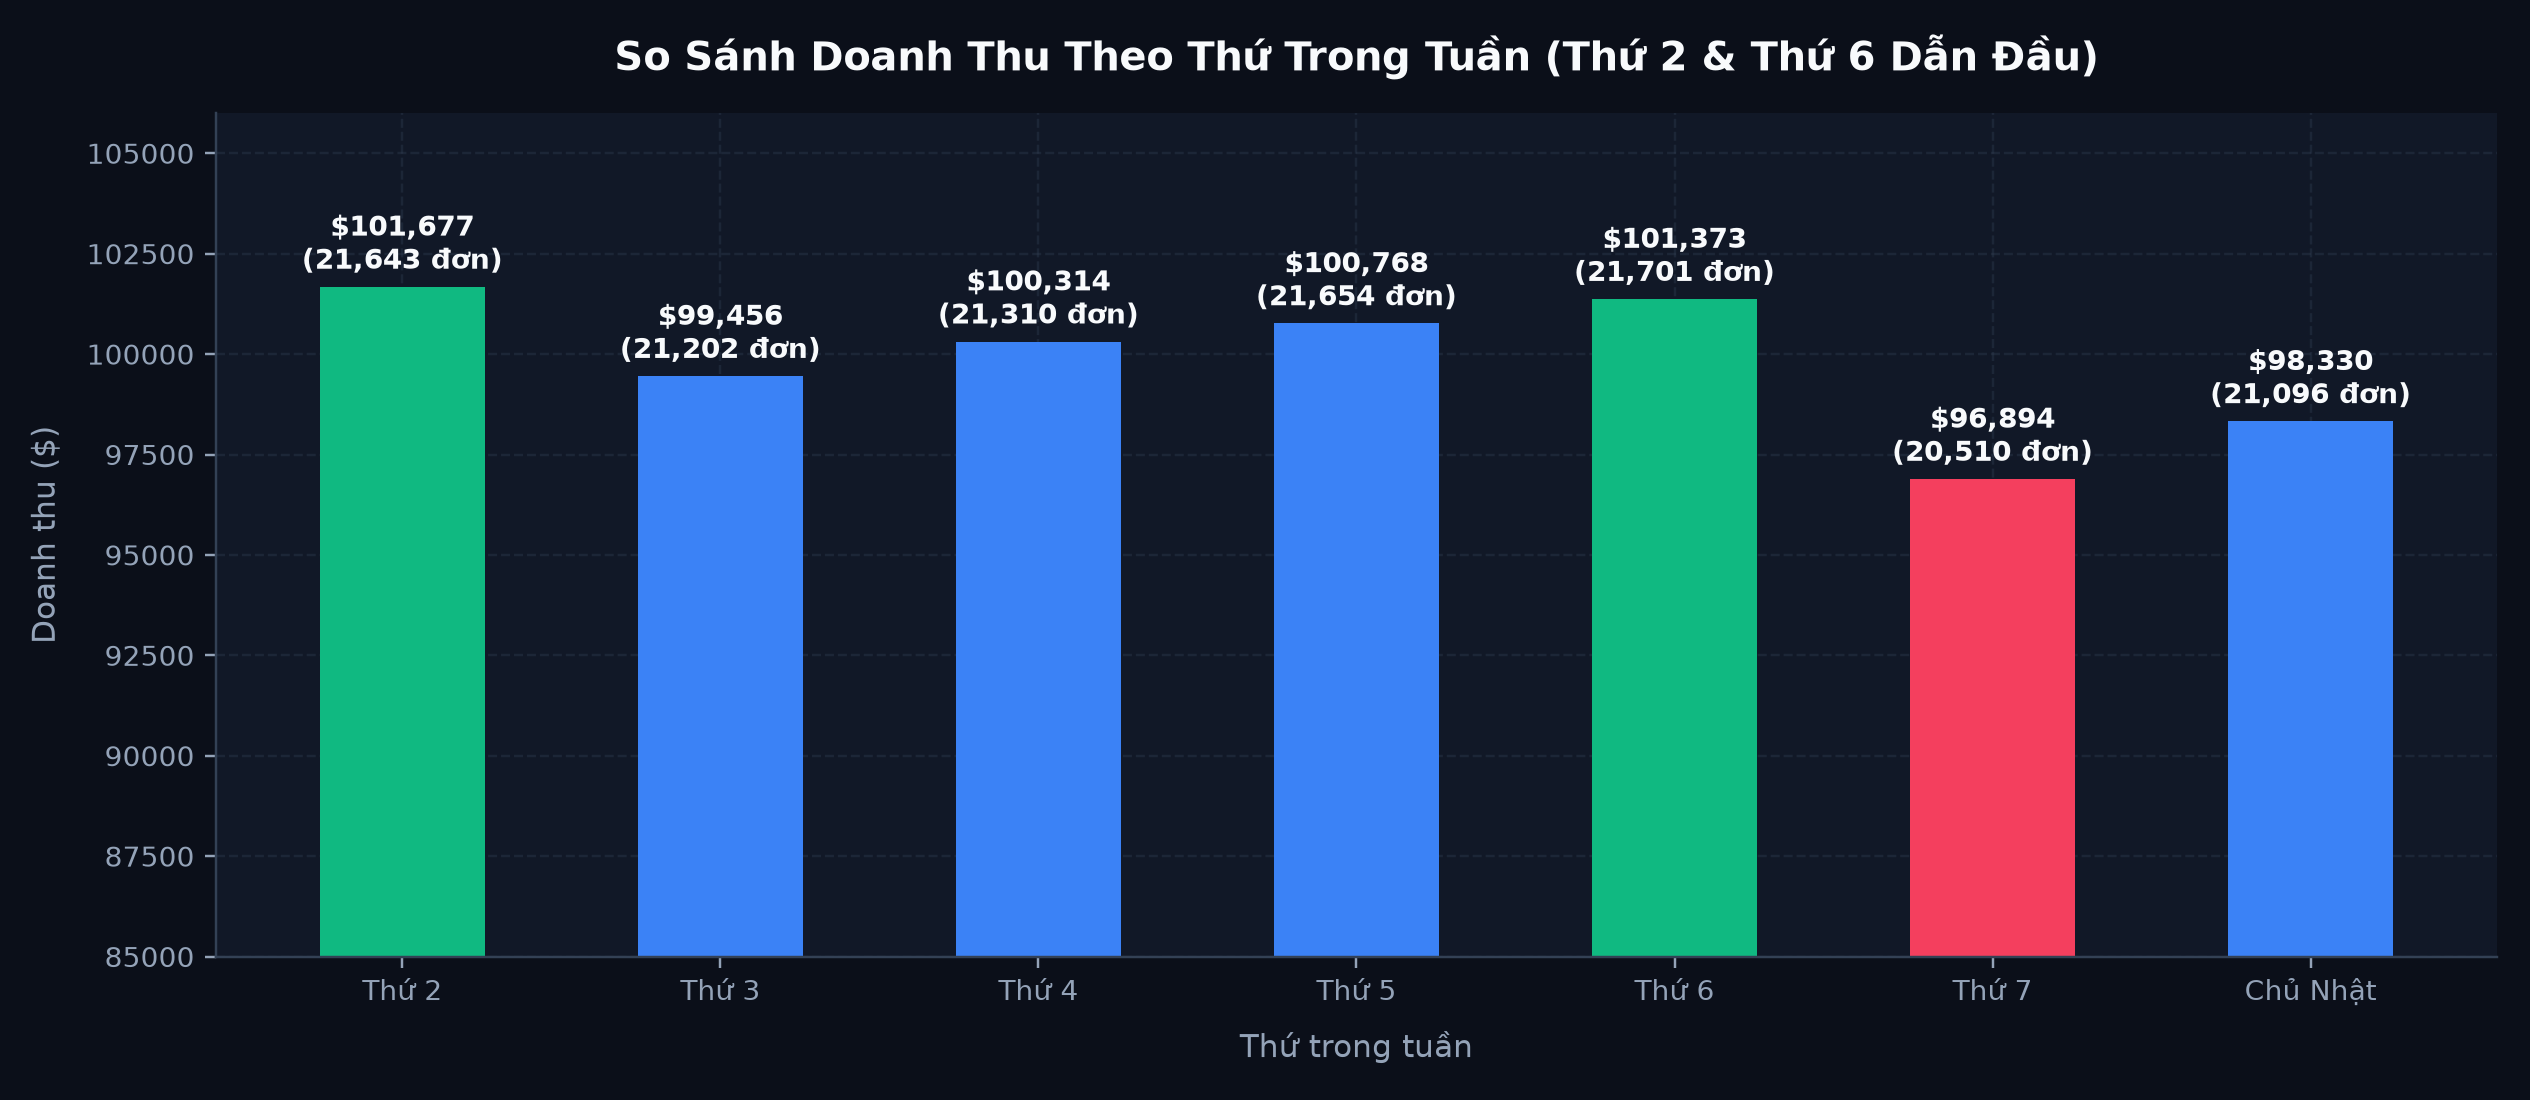

In [1]:
# Biểu đồ 10: Thứ Hai ($101,677) và Thứ Sáu ($101,373) dẫn đầu tuần (docs/charts/slide18_day_of_week_sales.png)
display(Image(filename=str(PROJECT_ROOT / "docs" / "charts" / "slide18_day_of_week_sales.png")))

### Biểu đồ 11: So sánh Đường cong Nhịp độ Khung Giờ giữa Ngày thường (Weekday) vs. Cuối tuần (Weekend)
- **Nhận xét:** Vào các ngày làm việc trong tuần (Thứ 2 – Thứ 6), đỉnh 08h–10h sáng cao vượt trội so với cuối tuần do lưu lượng khách công sở đi làm.

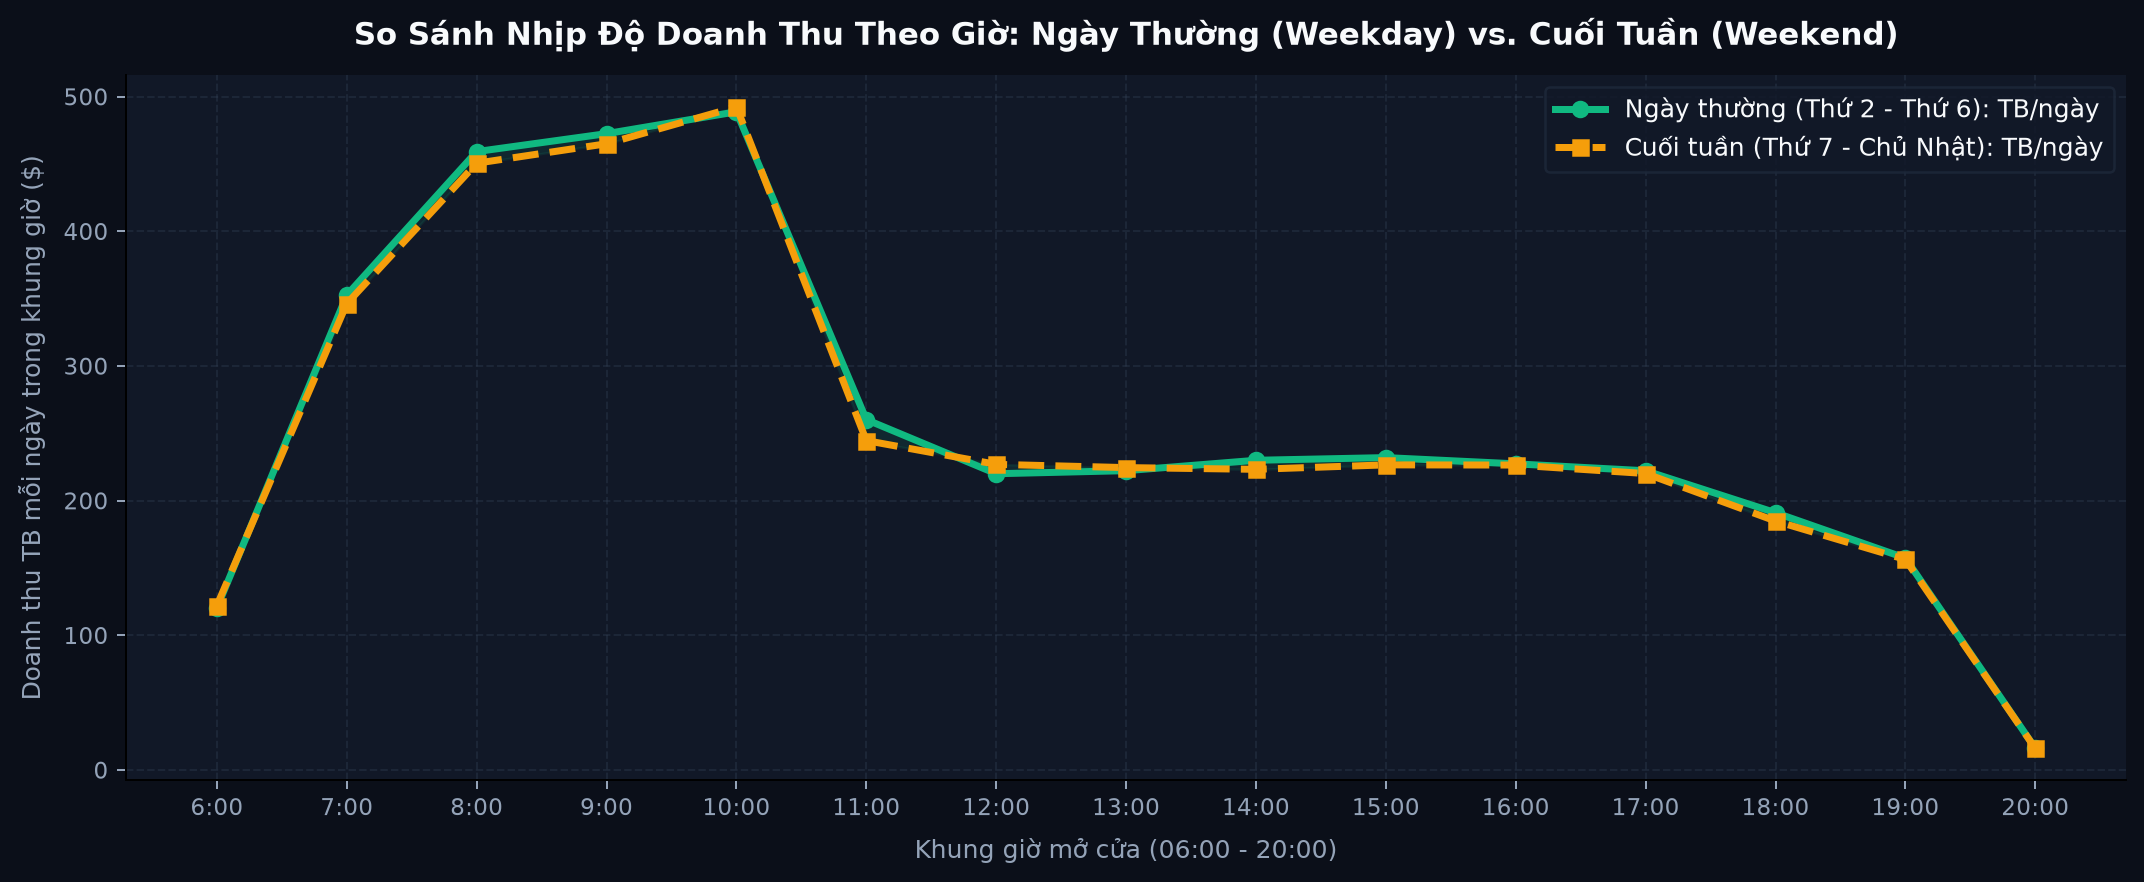

In [1]:
# Biểu đồ 11: Đường cong doanh thu TB/ngày theo từng khung giờ giữa Ngày thường và Cuối tuần (docs/charts/nb_chart11_weekday_vs_weekend_hourly.png)
display(Image(filename=str(PROJECT_ROOT / "docs" / "charts" / "nb_chart11_weekday_vs_weekend_hourly.png")))

### Biểu đồ 12: Ma Trận Nhiệt Bán Hàng 2 Chiều (Heatmap: Thứ Trong Tuần × Khung Giờ)
- **Nhận xét:** Định vị vùng quá tải cực đại tại dải giờ 08:00 – 10:00 sáng các ngày trong tuần (~$12.0k – $13.3k mỗi ô giờ).

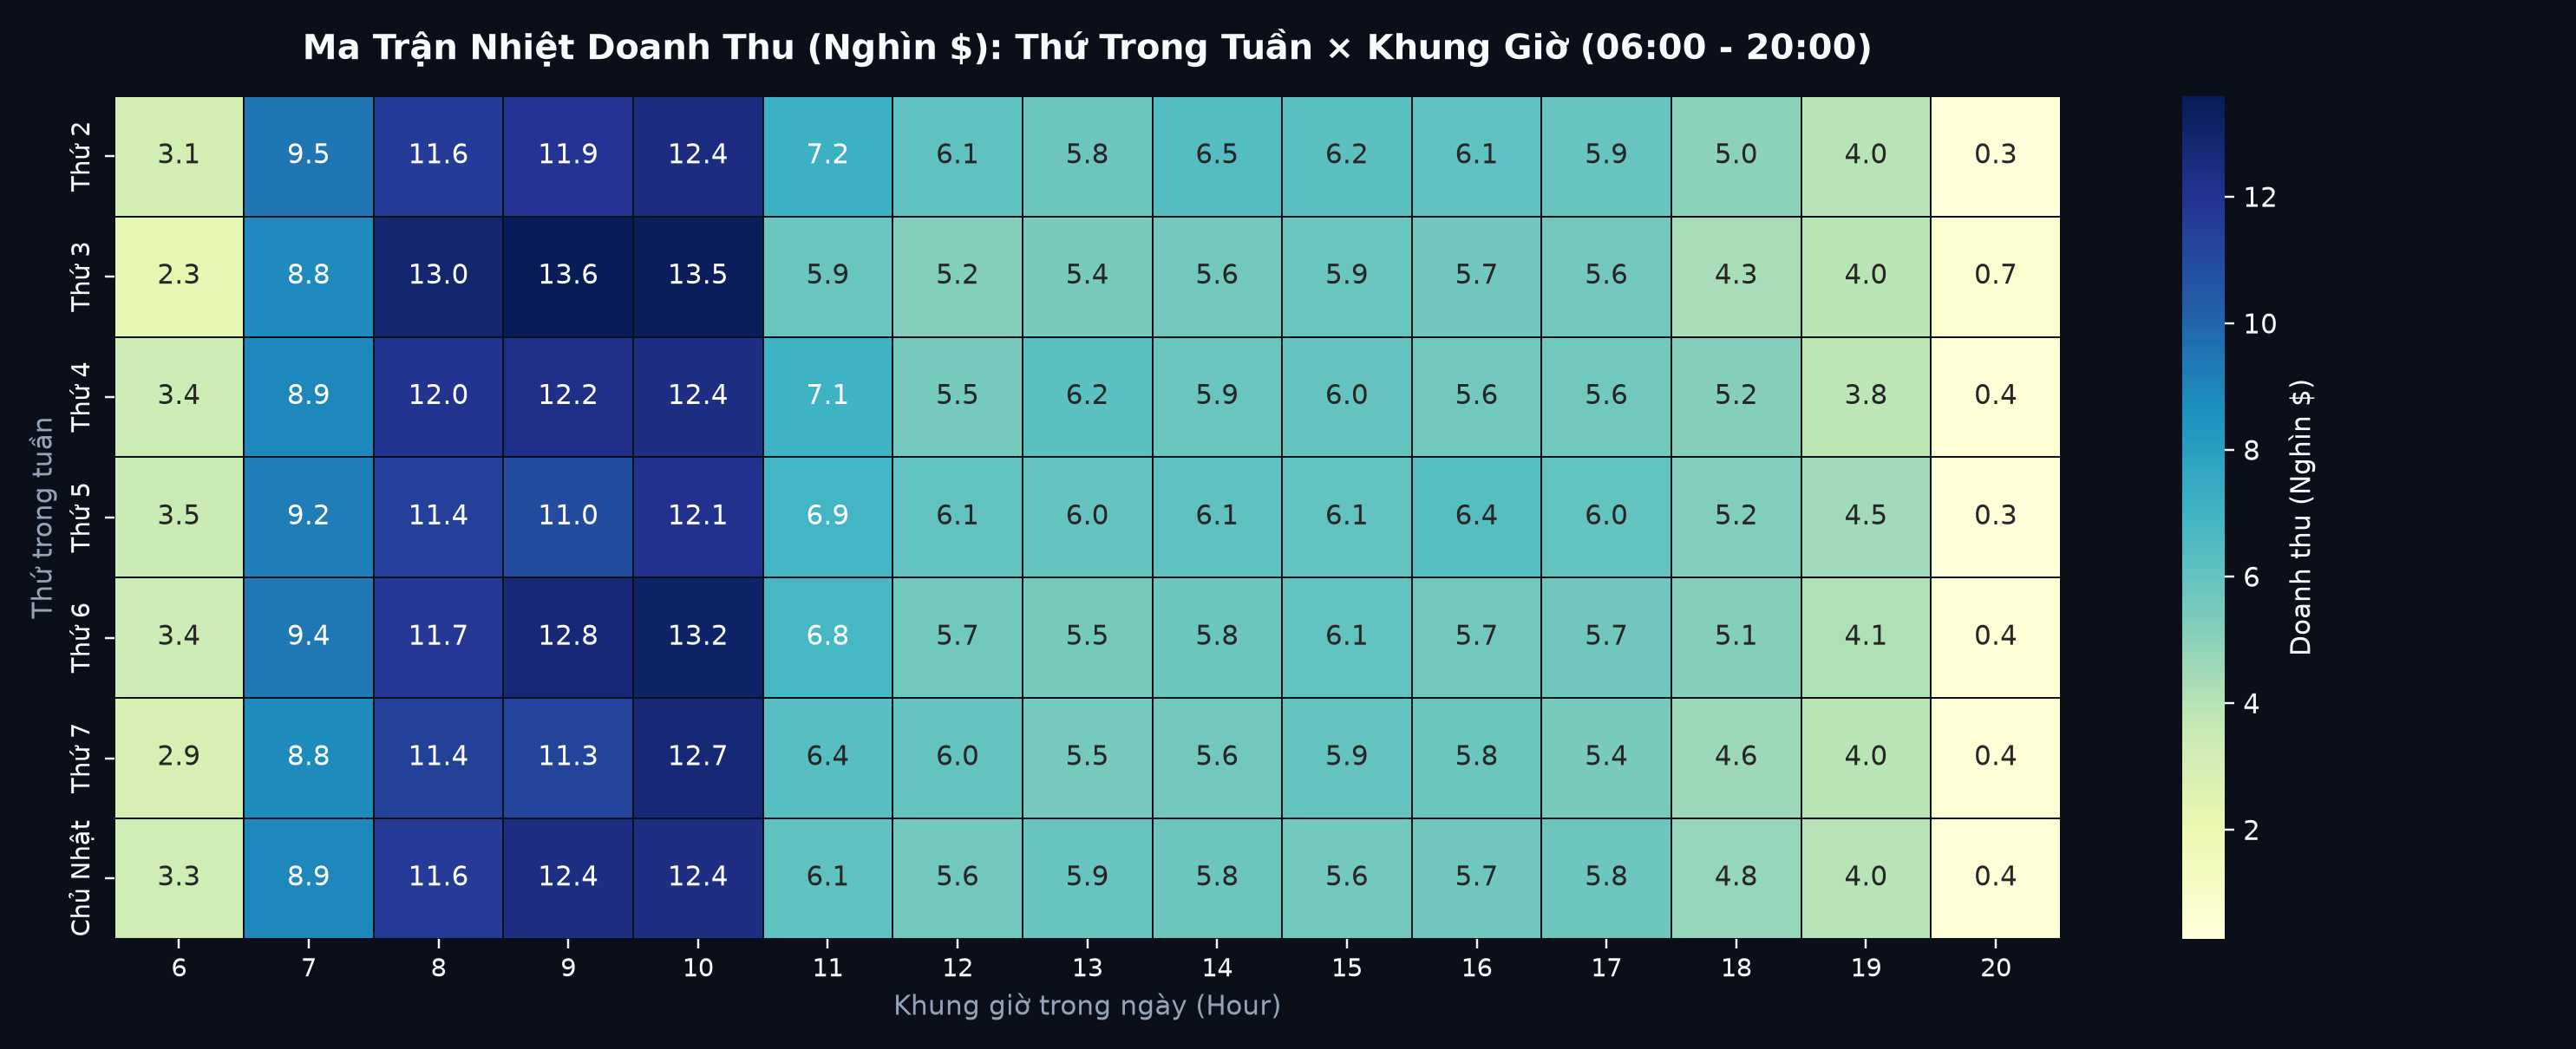

In [1]:
# Biểu đồ 12: Heatmap 7 Thứ x 15 Khung giờ (docs/charts/slide19_heatmap_day_hour.png)
display(Image(filename=str(PROJECT_ROOT / "docs" / "charts" / "slide19_heatmap_day_hour.png")))

### Biểu đồ 13: Ma Trận Nhiệt Theo Mùa Vụ (Heatmap: Tháng Kinh Doanh × Khung Giờ)
- **Nhận xét:** Vào Tháng 5 và Tháng 6, không chỉ khung giờ sáng bùng nổ (~$20k–$21k/giờ) mà cả khung giờ chiều 14h–17h cũng tăng gần gấp đôi so với Tháng 1–2.

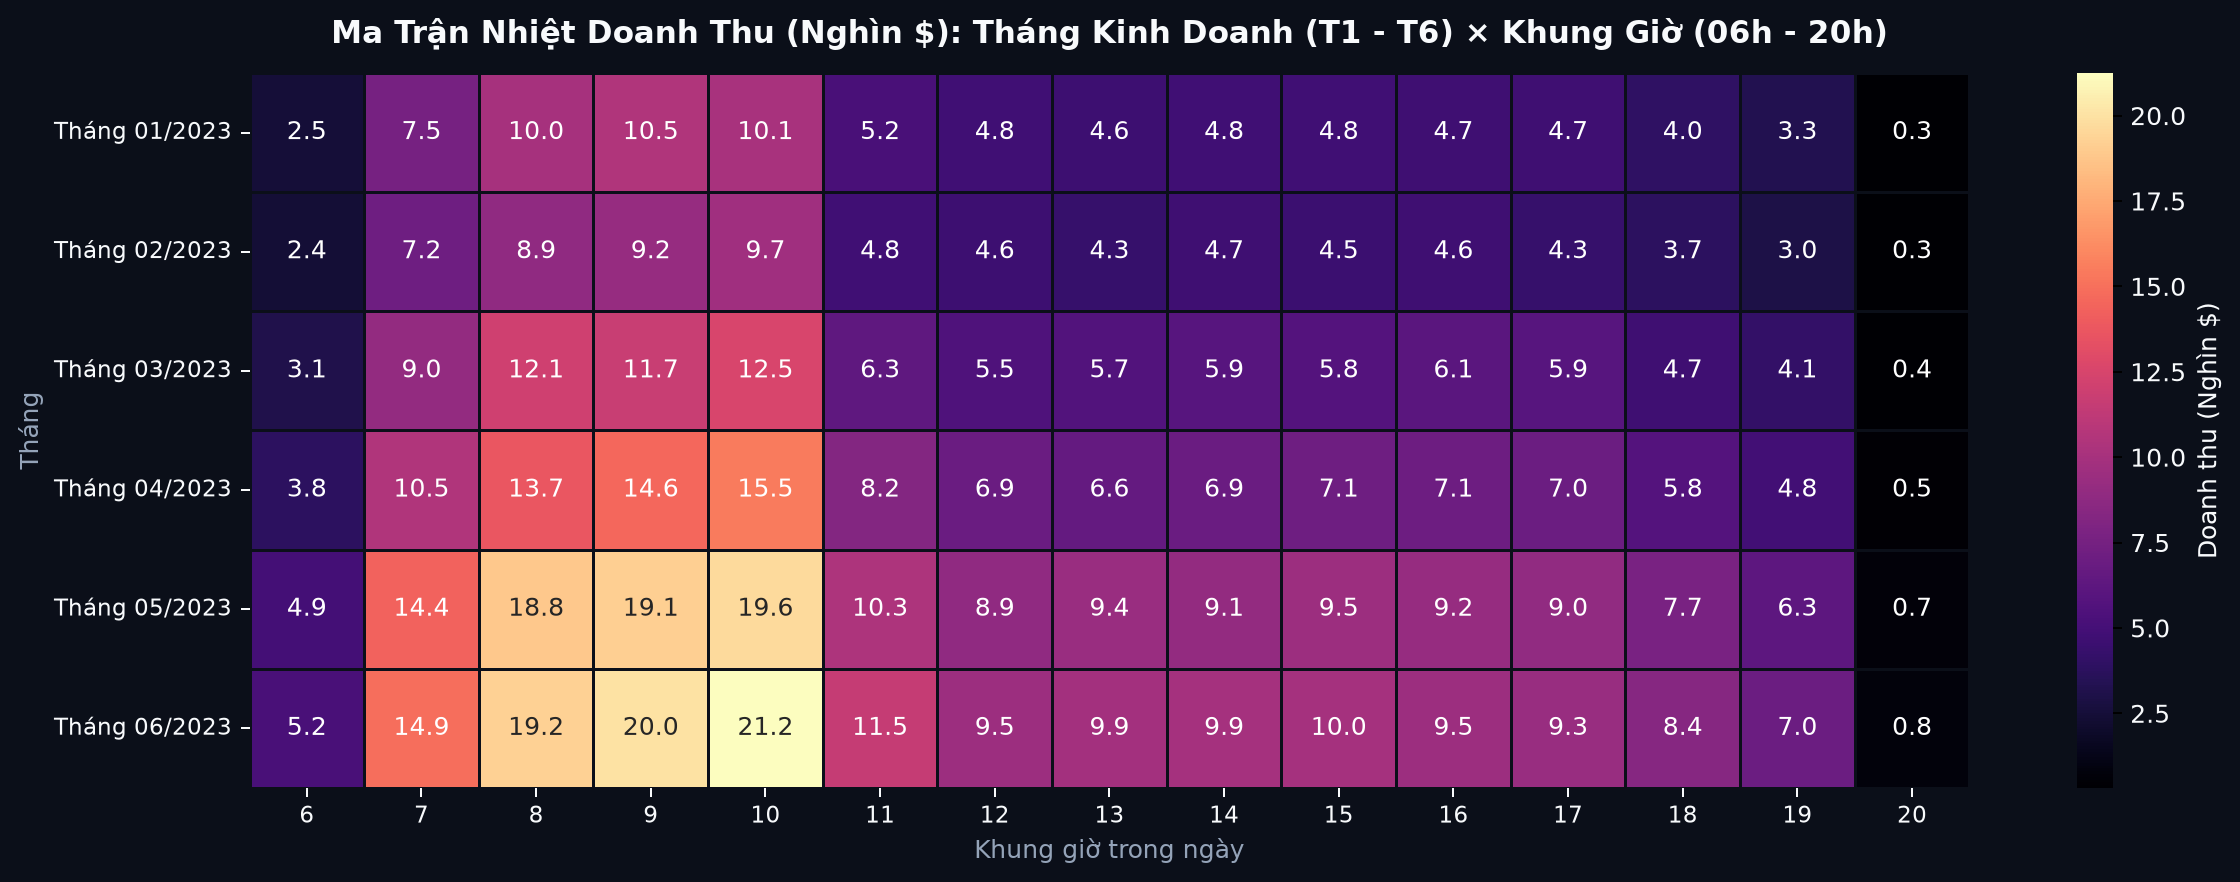

In [1]:
# Biểu đồ 13: Heatmap 6 Tháng x 15 Khung giờ (docs/charts/nb_chart13_heatmap_month_hour.png)
display(Image(filename=str(PROJECT_ROOT / "docs" / "charts" / "nb_chart13_heatmap_month_hour.png")))

---
## PHẦN 4: PHÂN TÍCH SẢN PHẨM & DANH MỤC — "SẢN PHẨM NÀO DOANH THU CAO?" (PHÂN HỆ NGỌC PHƯỚC)
### Biểu đồ 14: Xếp hạng Doanh thu & Tỷ trọng 9 Danh mục Sản phẩm (product_category)
- **Nhận xét:** Coffee ($269,952.45 - 38.63%) và Tea ($196,405.95 - 28.11%) chiếm 2/3 tổng doanh thu toàn chuỗi.

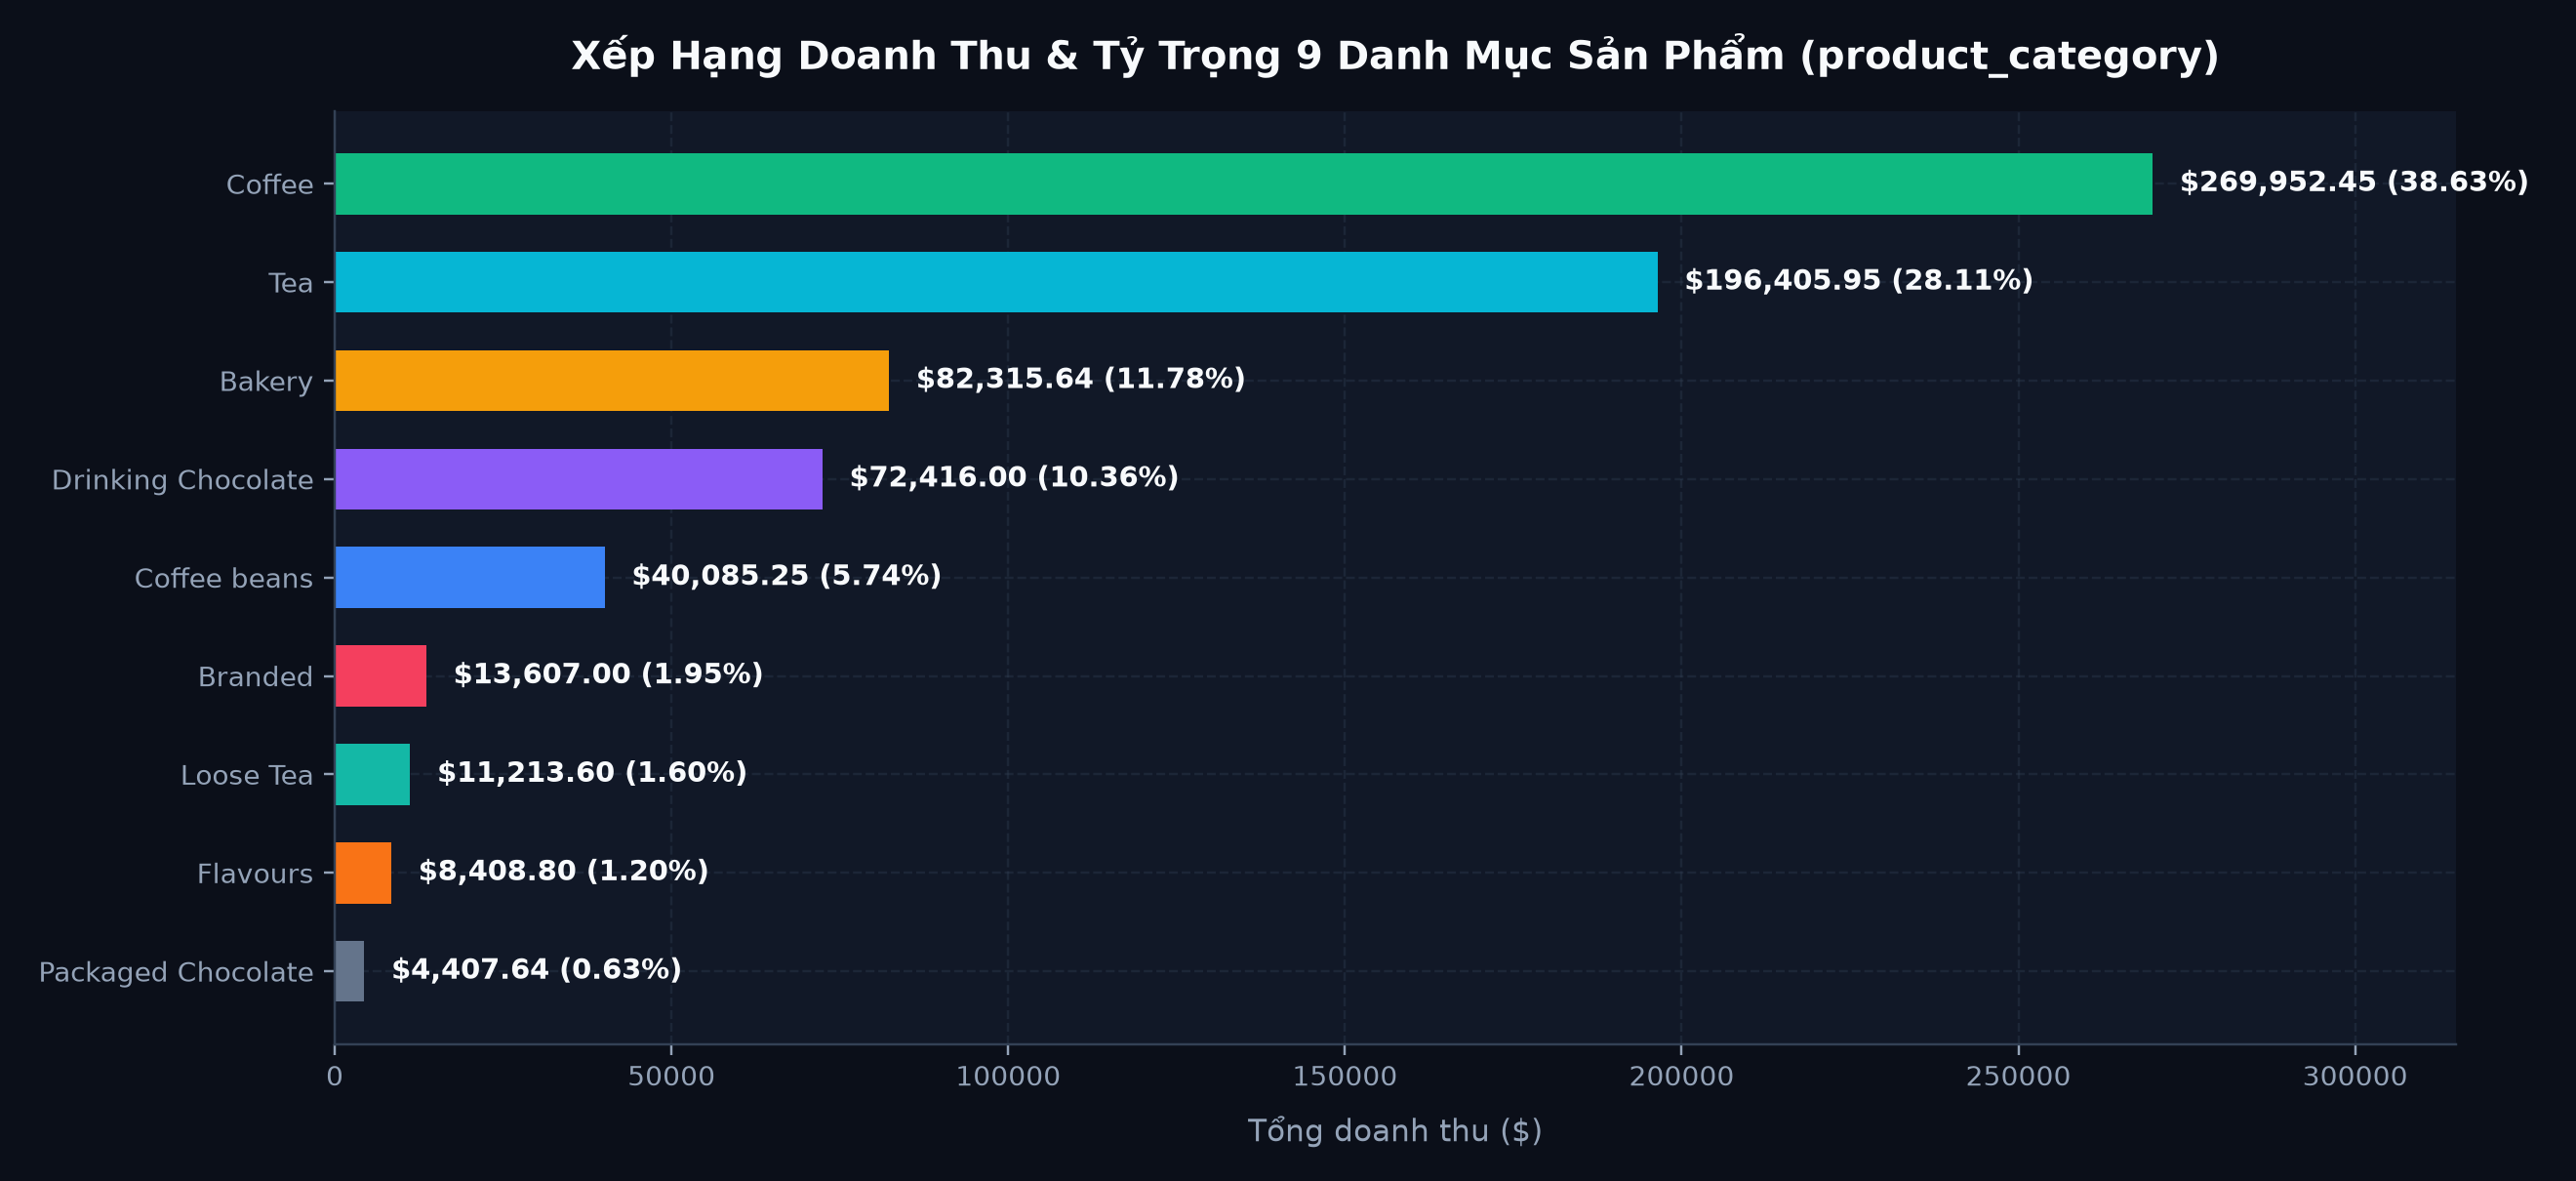

In [1]:
# Biểu đồ 14: Xếp hạng 9 danh mục lớn (docs/charts/slide20_category_donut_bar.png)
display(Image(filename=str(PROJECT_ROOT / "docs" / "charts" / "slide20_category_donut_bar.png")))

### Biểu đồ 15: Biểu đồ Pareto 80/20 trên 9 Danh mục Sản phẩm
- **Nhận xét:** Top 4 danh mục (Coffee, Tea, Bakery, Drinking Chocolate) đóng góp tới 88.88% tổng doanh thu.

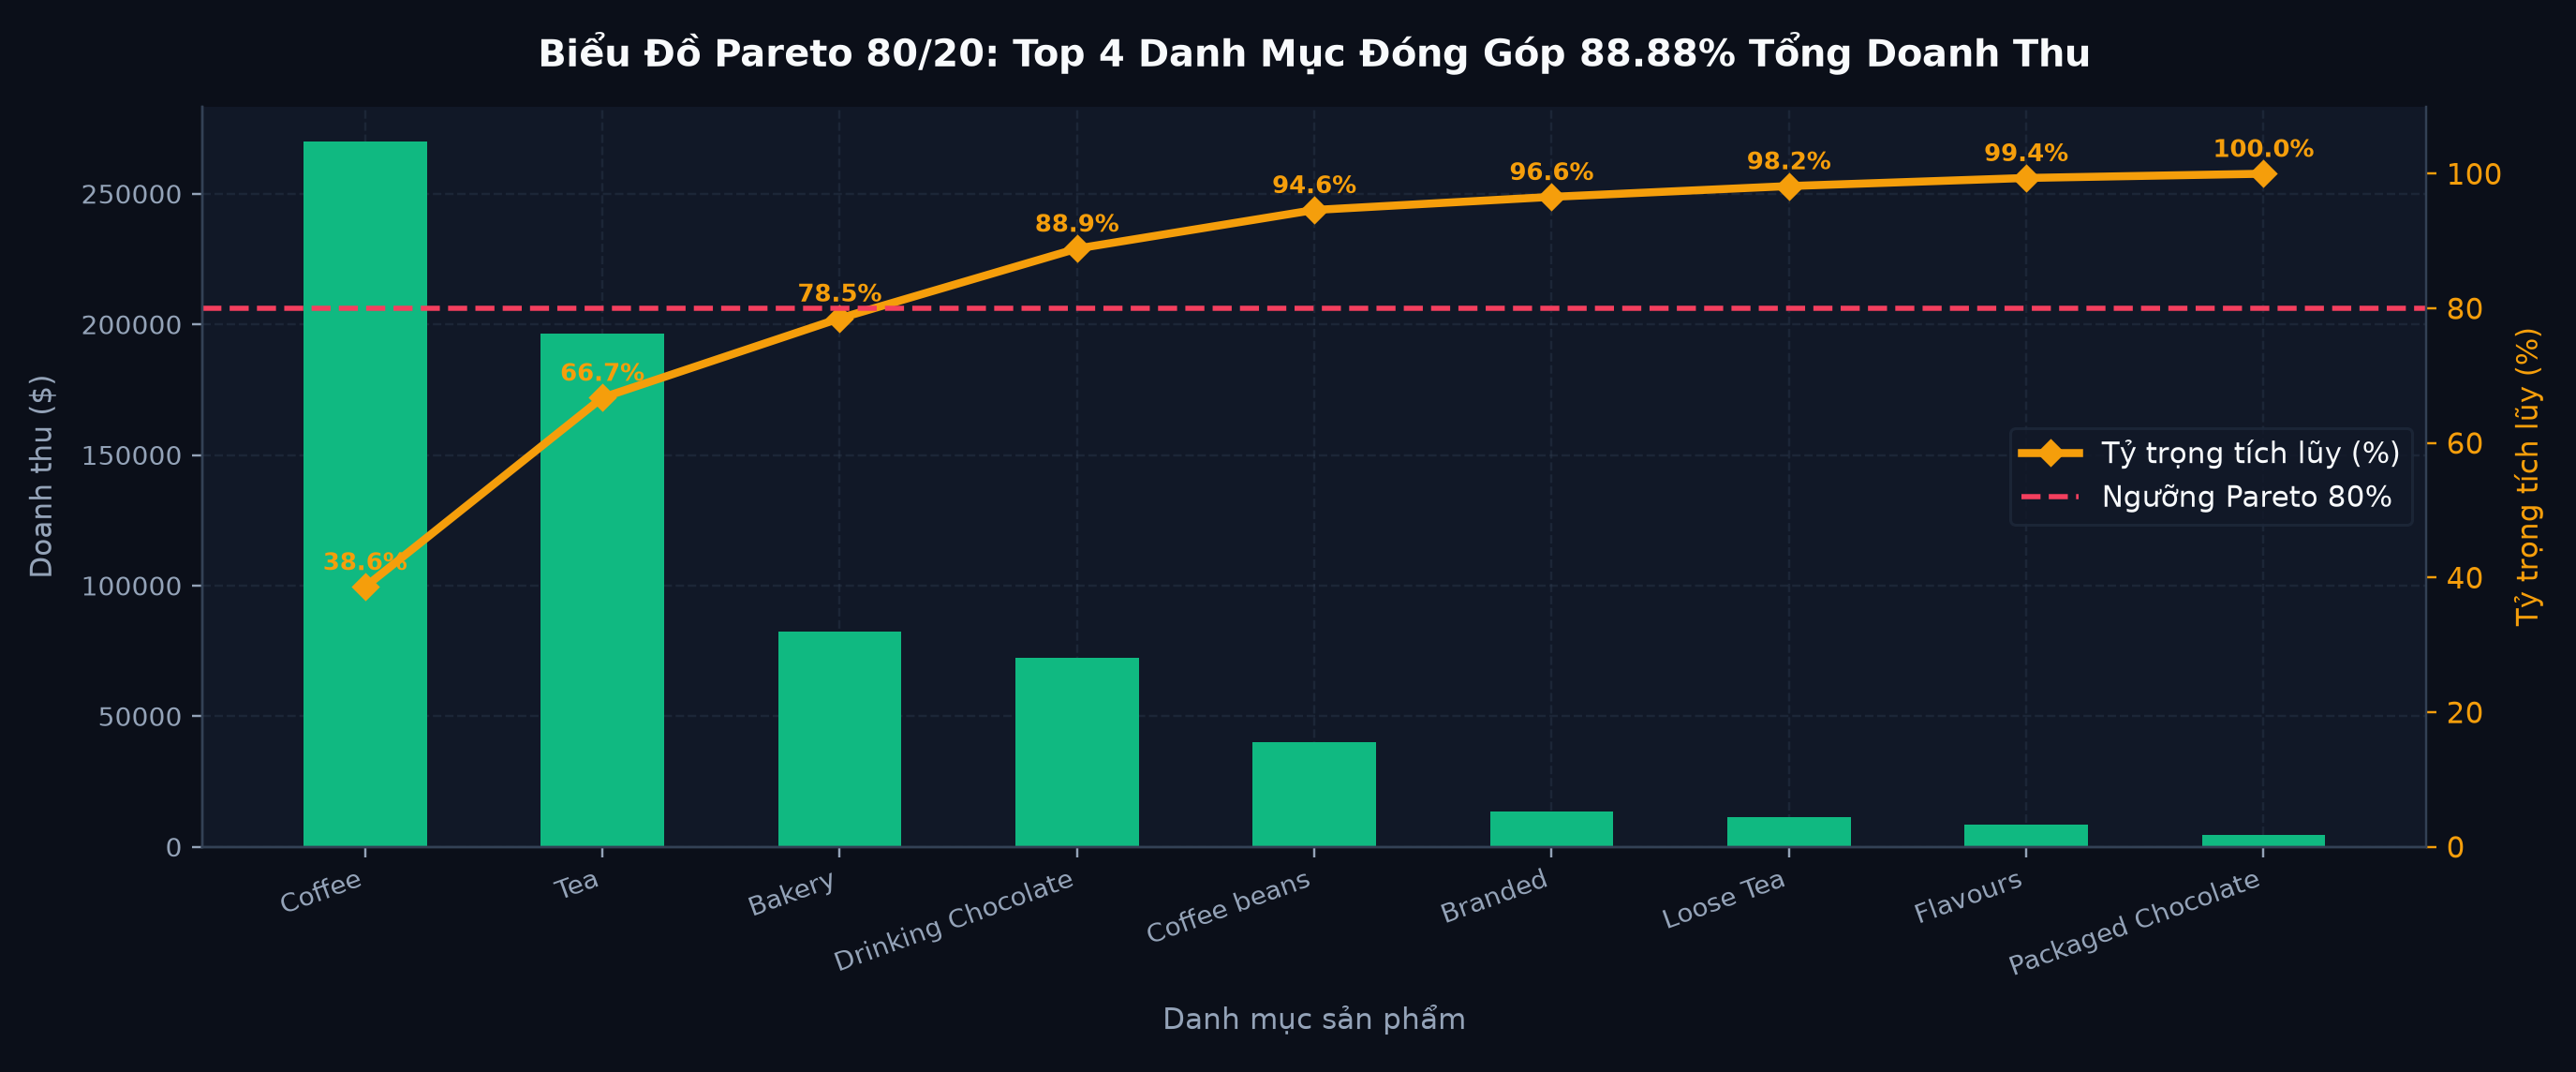

In [1]:
# Biểu đồ 15: Đường tích lũy Pareto chứng minh Top 4 danh mục chiếm 88.88% doanh thu (docs/charts/slide21_pareto_categories.png)
display(Image(filename=str(PROJECT_ROOT / "docs" / "charts" / "slide21_pareto_categories.png")))

### Biểu đồ 16: Top 10 Dòng Sản phẩm Chủ lực (product_type)
- **Nhận xét:** Barista Espresso dẫn đầu về doanh thu ($91,406.20), trong khi Brewed Chai tea dẫn đầu về số lượng ly bán ra (26,250 ly).

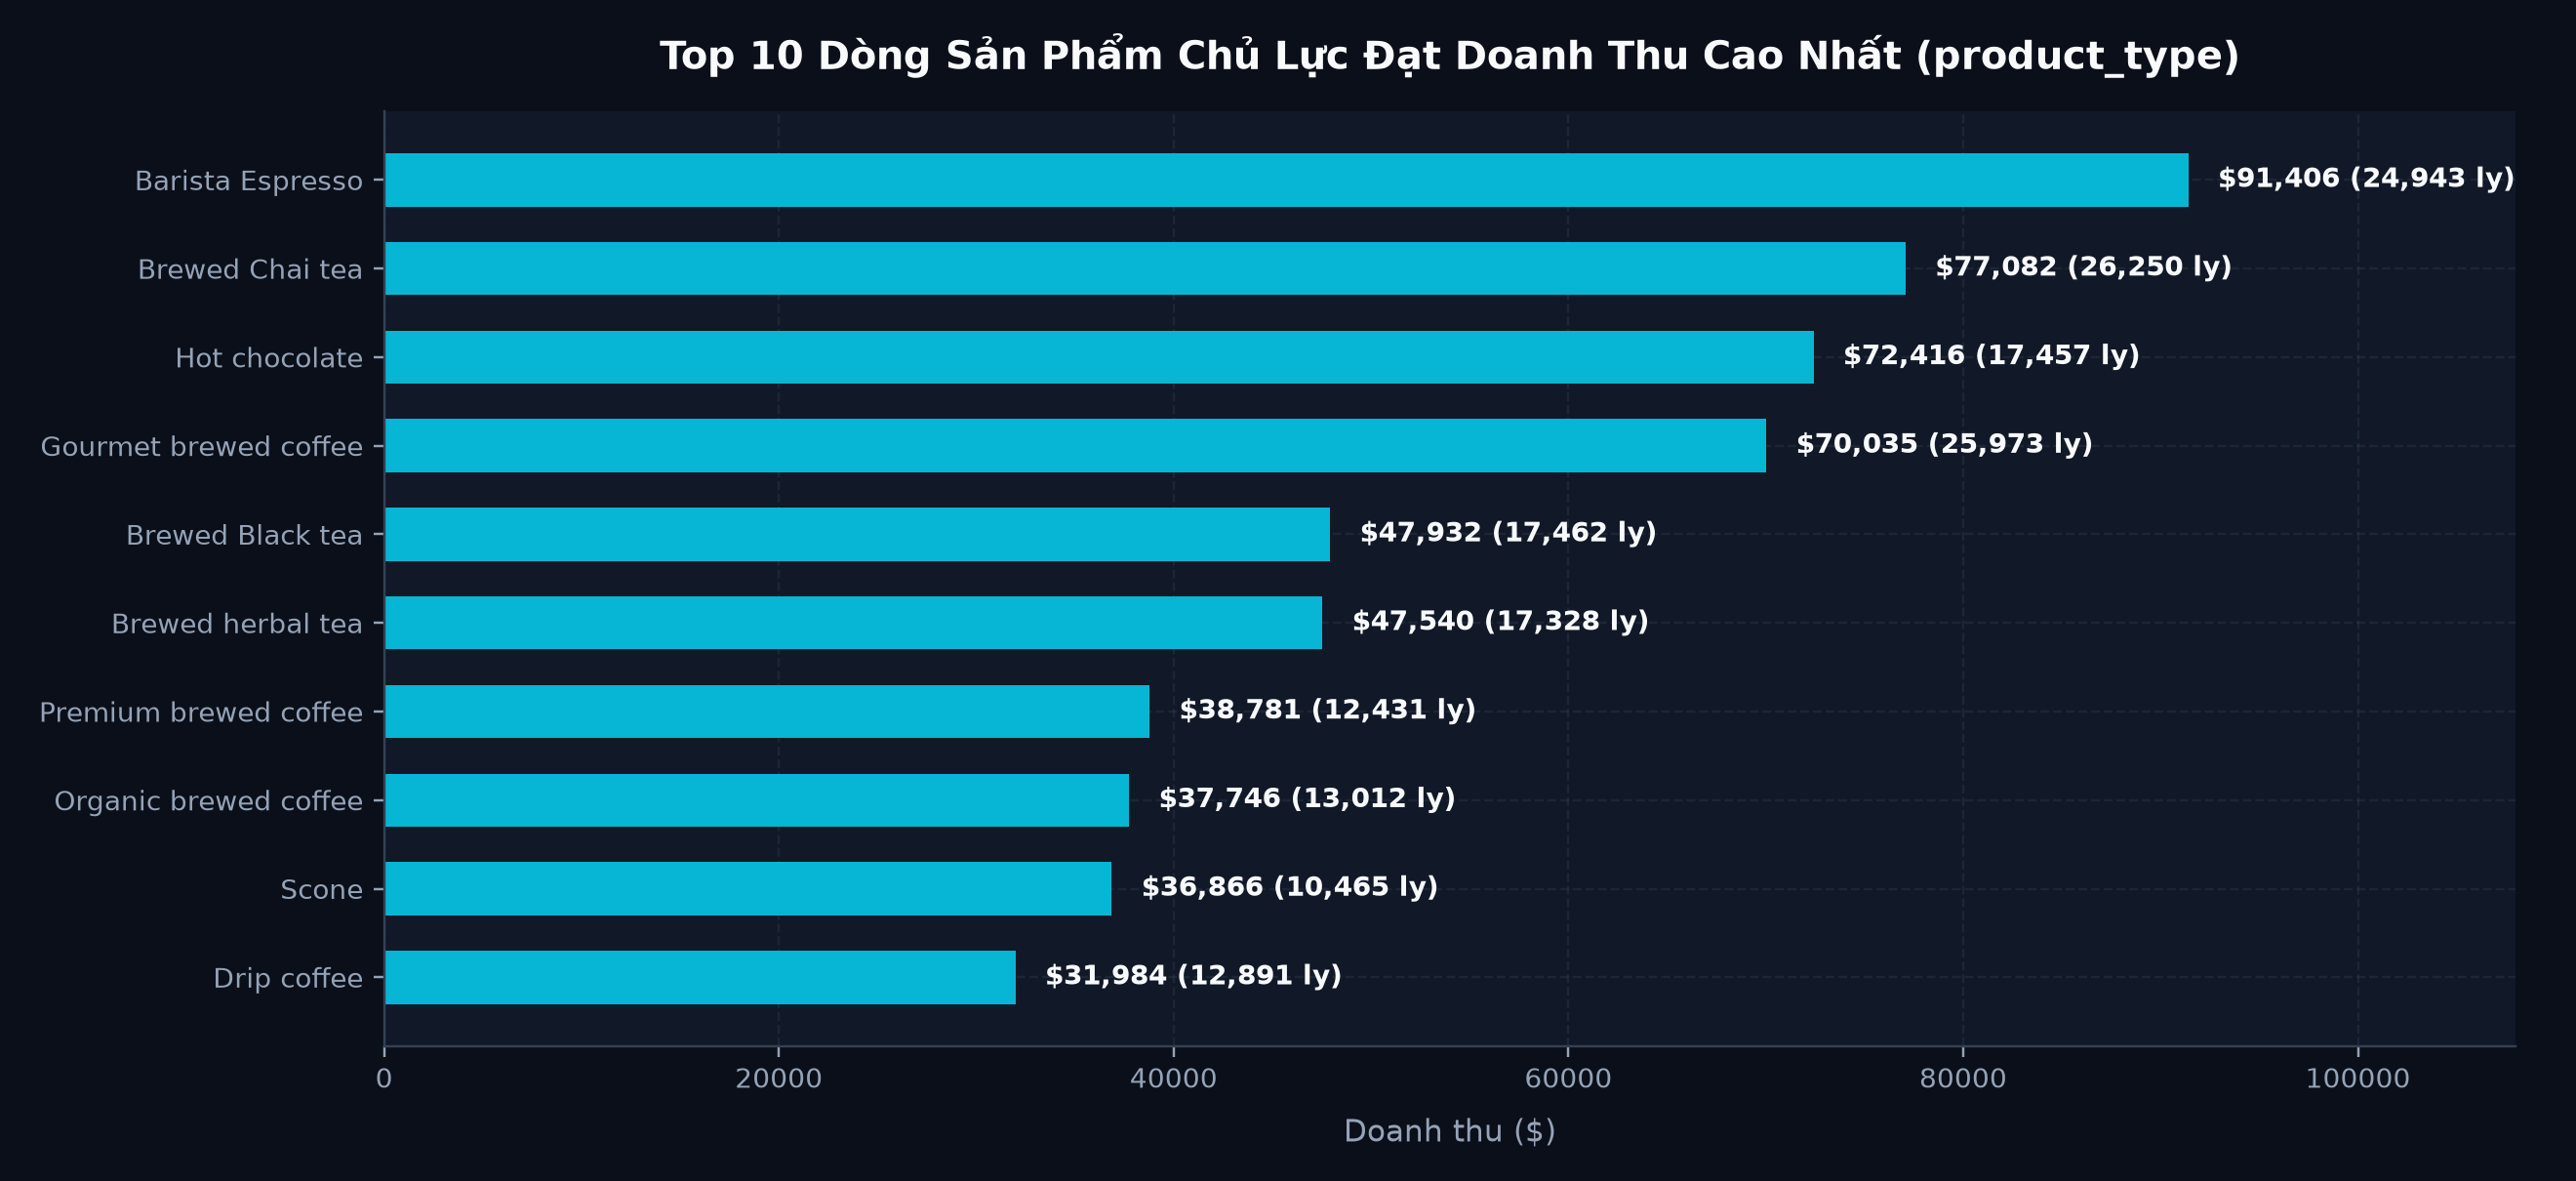

In [1]:
# Biểu đồ 16: Top 10 product_type (docs/charts/slide22_top10_product_types.png)
display(Image(filename=str(PROJECT_ROOT / "docs" / "charts" / "slide22_top10_product_types.png")))

### Biểu đồ 17: Top 10 Món Chi tiết Mang lại Doanh thu Cao nhất (product_detail — Cash Cows)
- **Nhận xét:** Sustainably Grown Organic Lg ($21,151.75), Dark chocolate Lg ($21,006.00) và Latte Rg ($19,112.25) là 3 món ăn khách nhất.

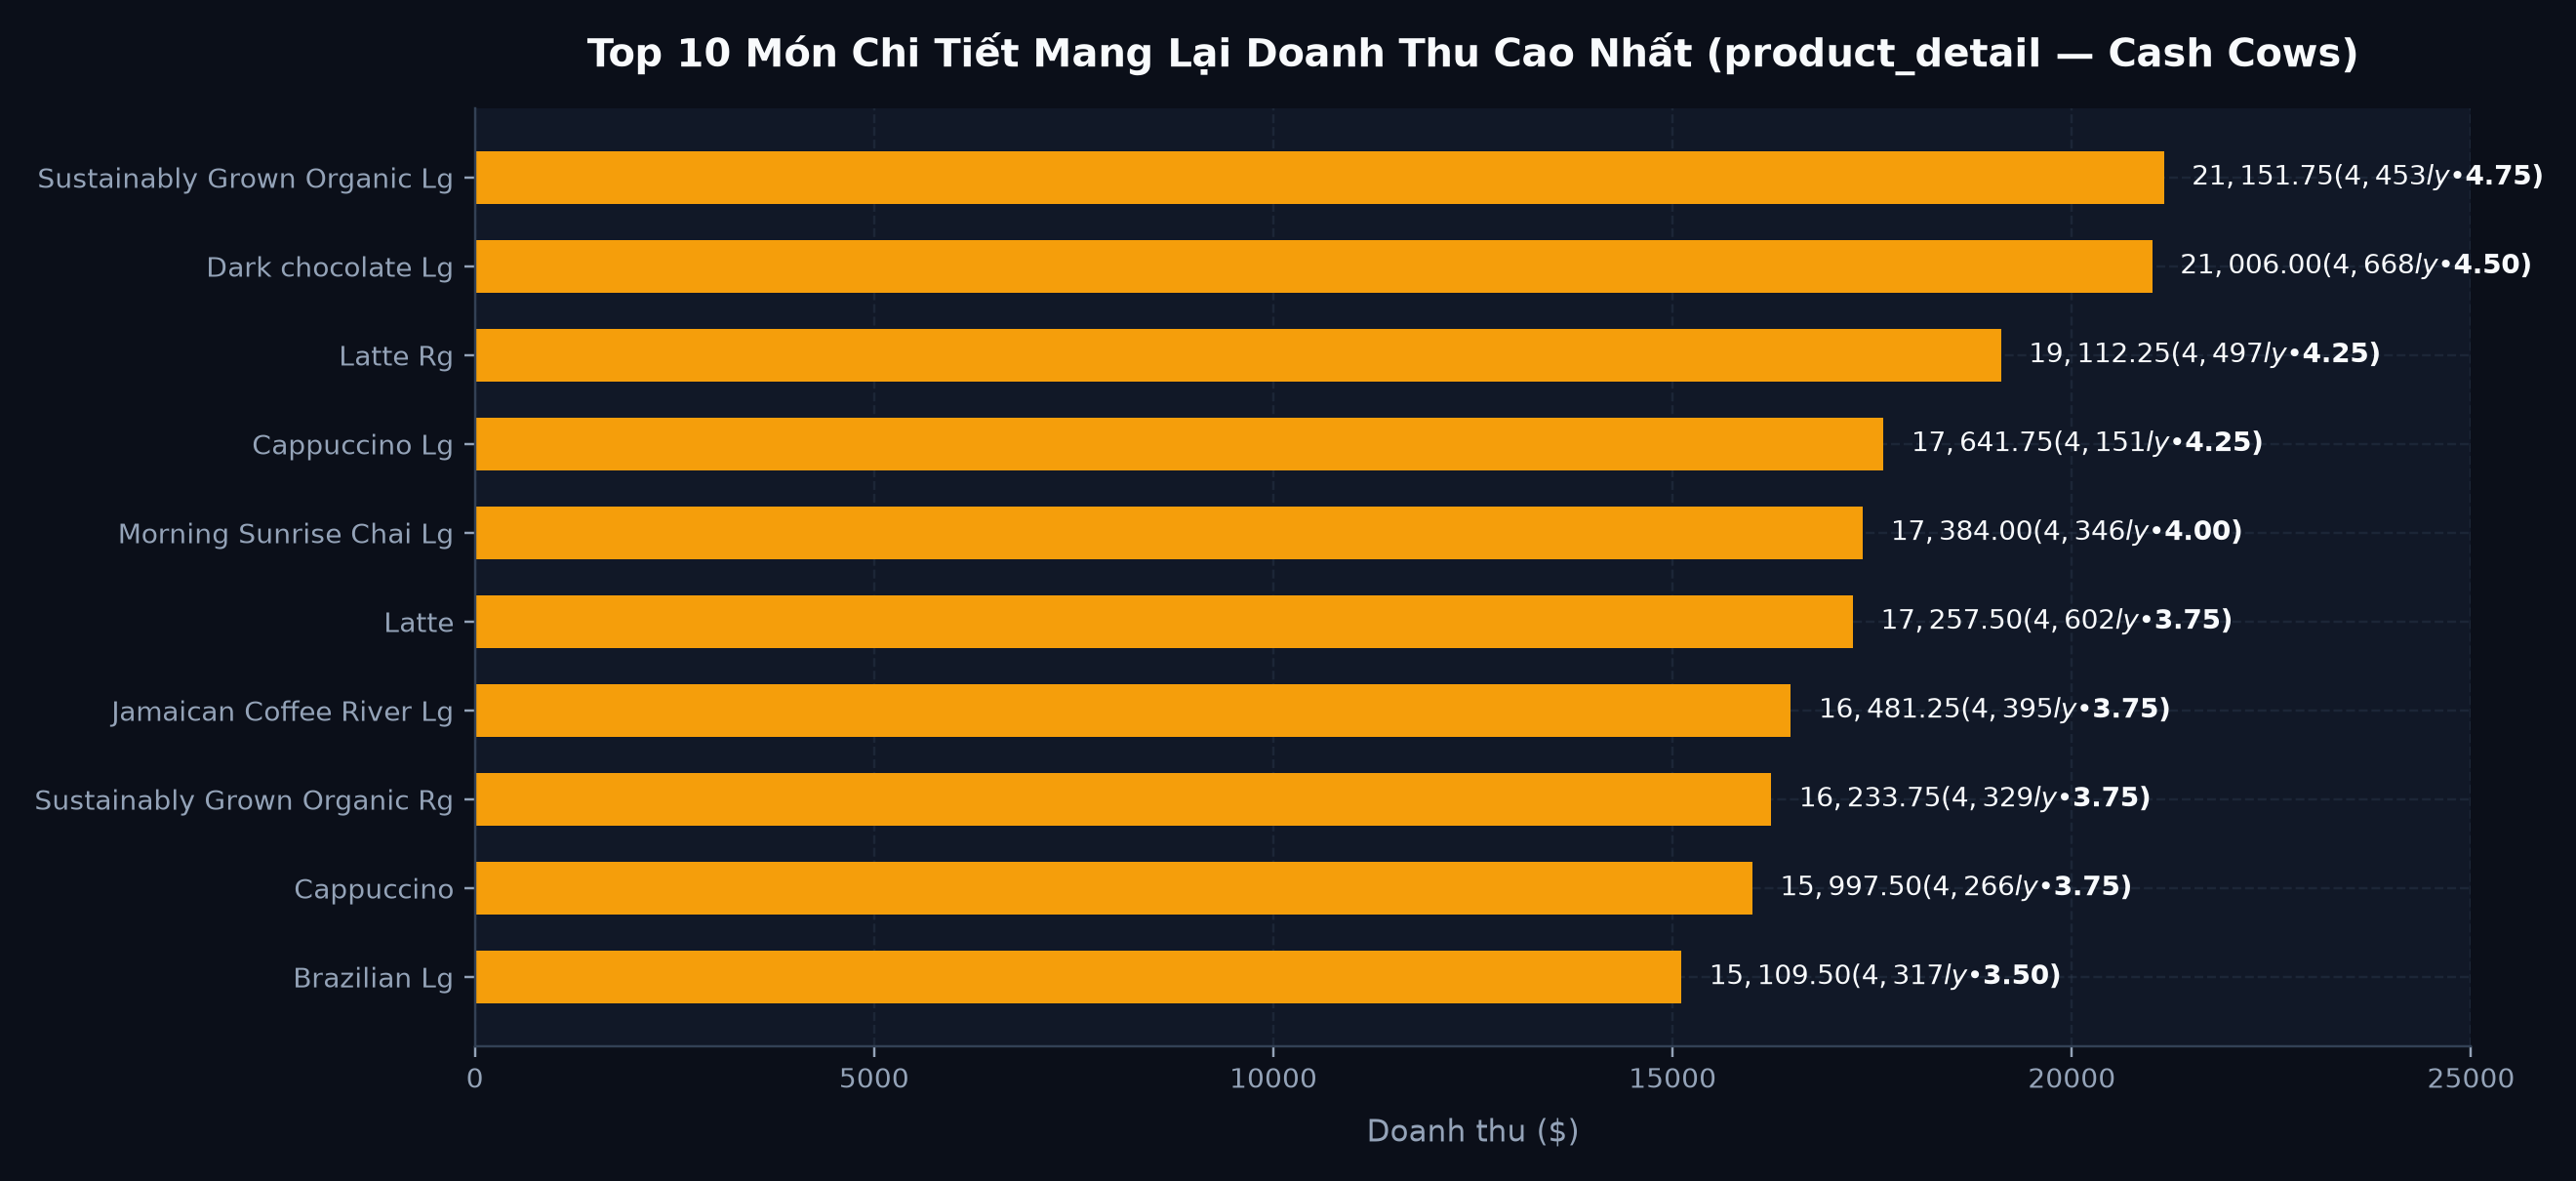

In [1]:
# Biểu đồ 17: Top 10 product_detail (docs/charts/slide23_top10_product_details.png)
display(Image(filename=str(PROJECT_ROOT / "docs" / "charts" / "slide23_top10_product_details.png")))

### Biểu đồ 18: Phân tích Hiệu ứng Kích cỡ Ly (Size Effect: Large vs. Regular vs. Small)
- **Nhận xét:** Các món Size Large (Lg) mang về doanh thu cao nhất ($247,891 - 35.5%), vượt qua cả nhóm Standard và Regular (Rg).

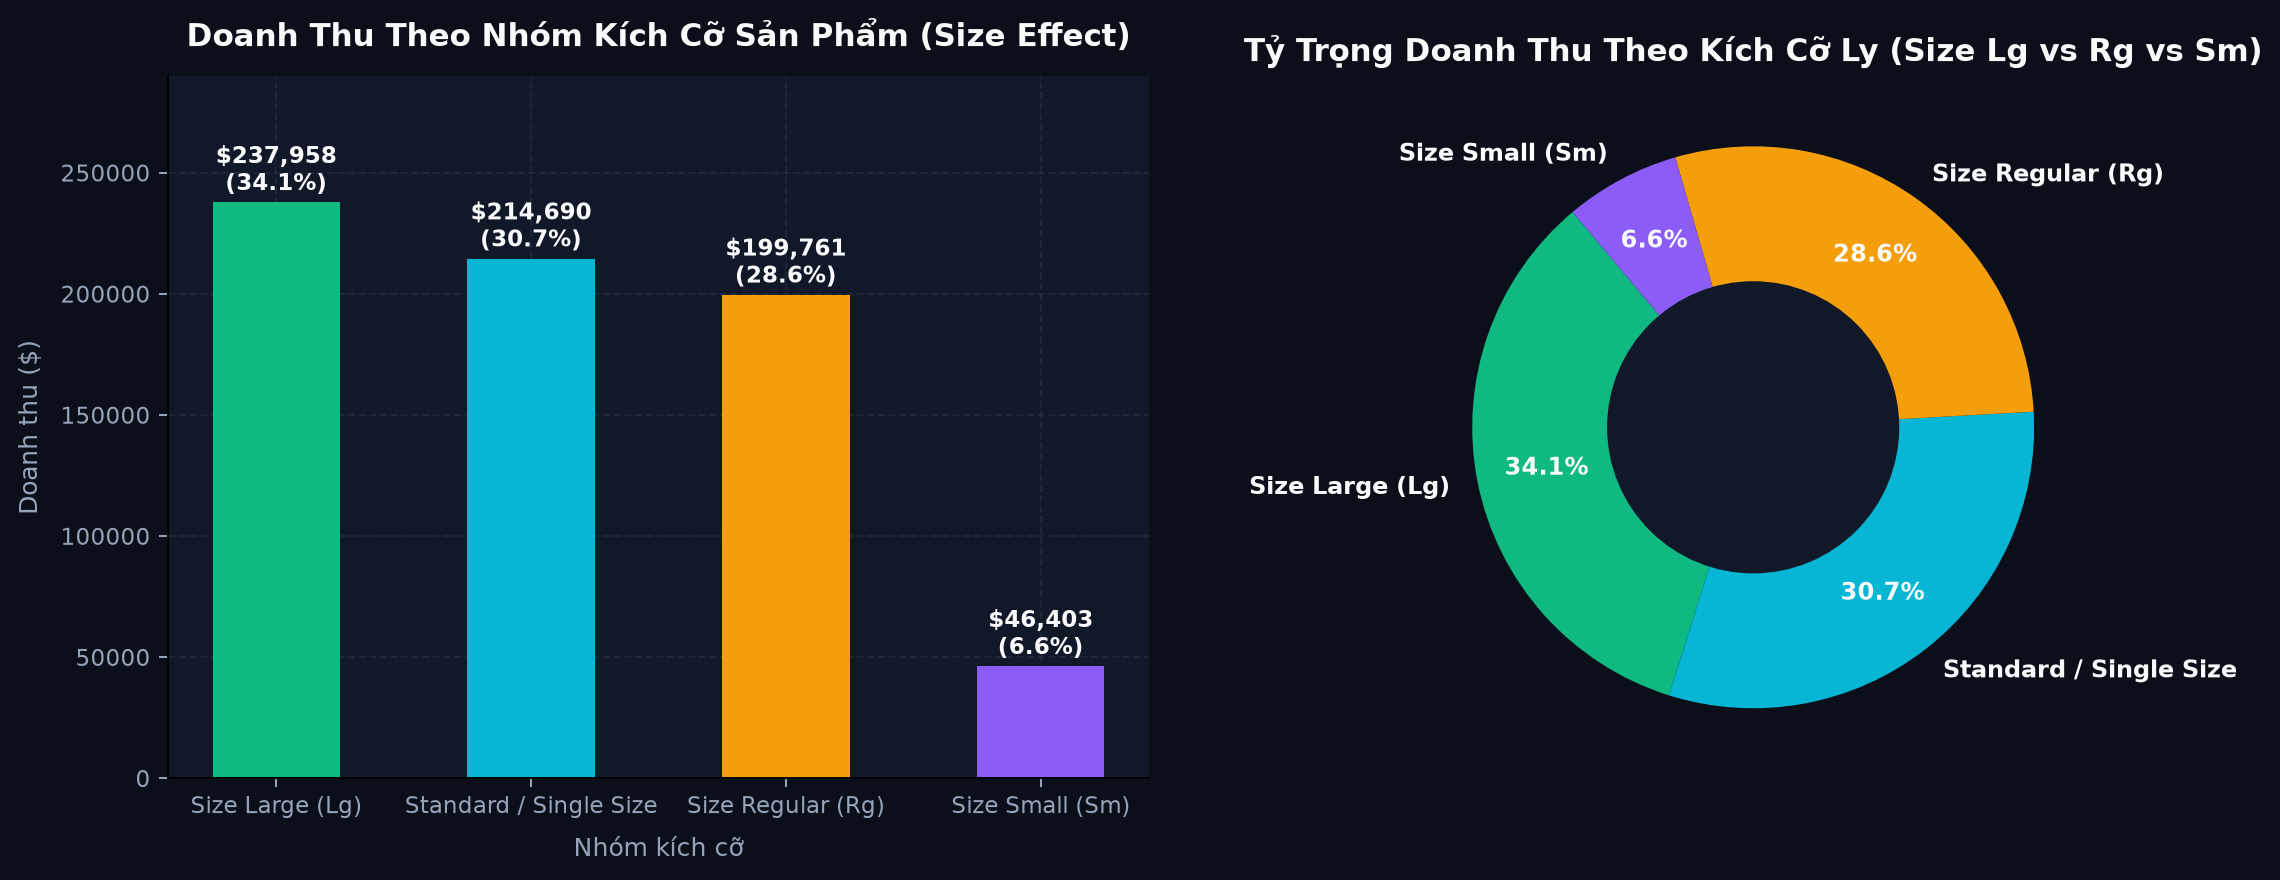

In [1]:
# Biểu đồ 18: Đánh giá đóng góp doanh thu theo kích cỡ ly (docs/charts/nb_chart18_size_effect_analysis.png)
display(Image(filename=str(PROJECT_ROOT / "docs" / "charts" / "nb_chart18_size_effect_analysis.png")))

### Biểu đồ 19: Ma trận Định giá — Đơn giá Trung bình vs. Sản lượng Bán (Scatter Bubble)
- **Nhận xét:** Vùng giá ngọt (Sweet-spot) $2.50 – $4.20 đạt sản lượng tiêu thụ cao nhất (17,000 – 26,250 ly/dòng).

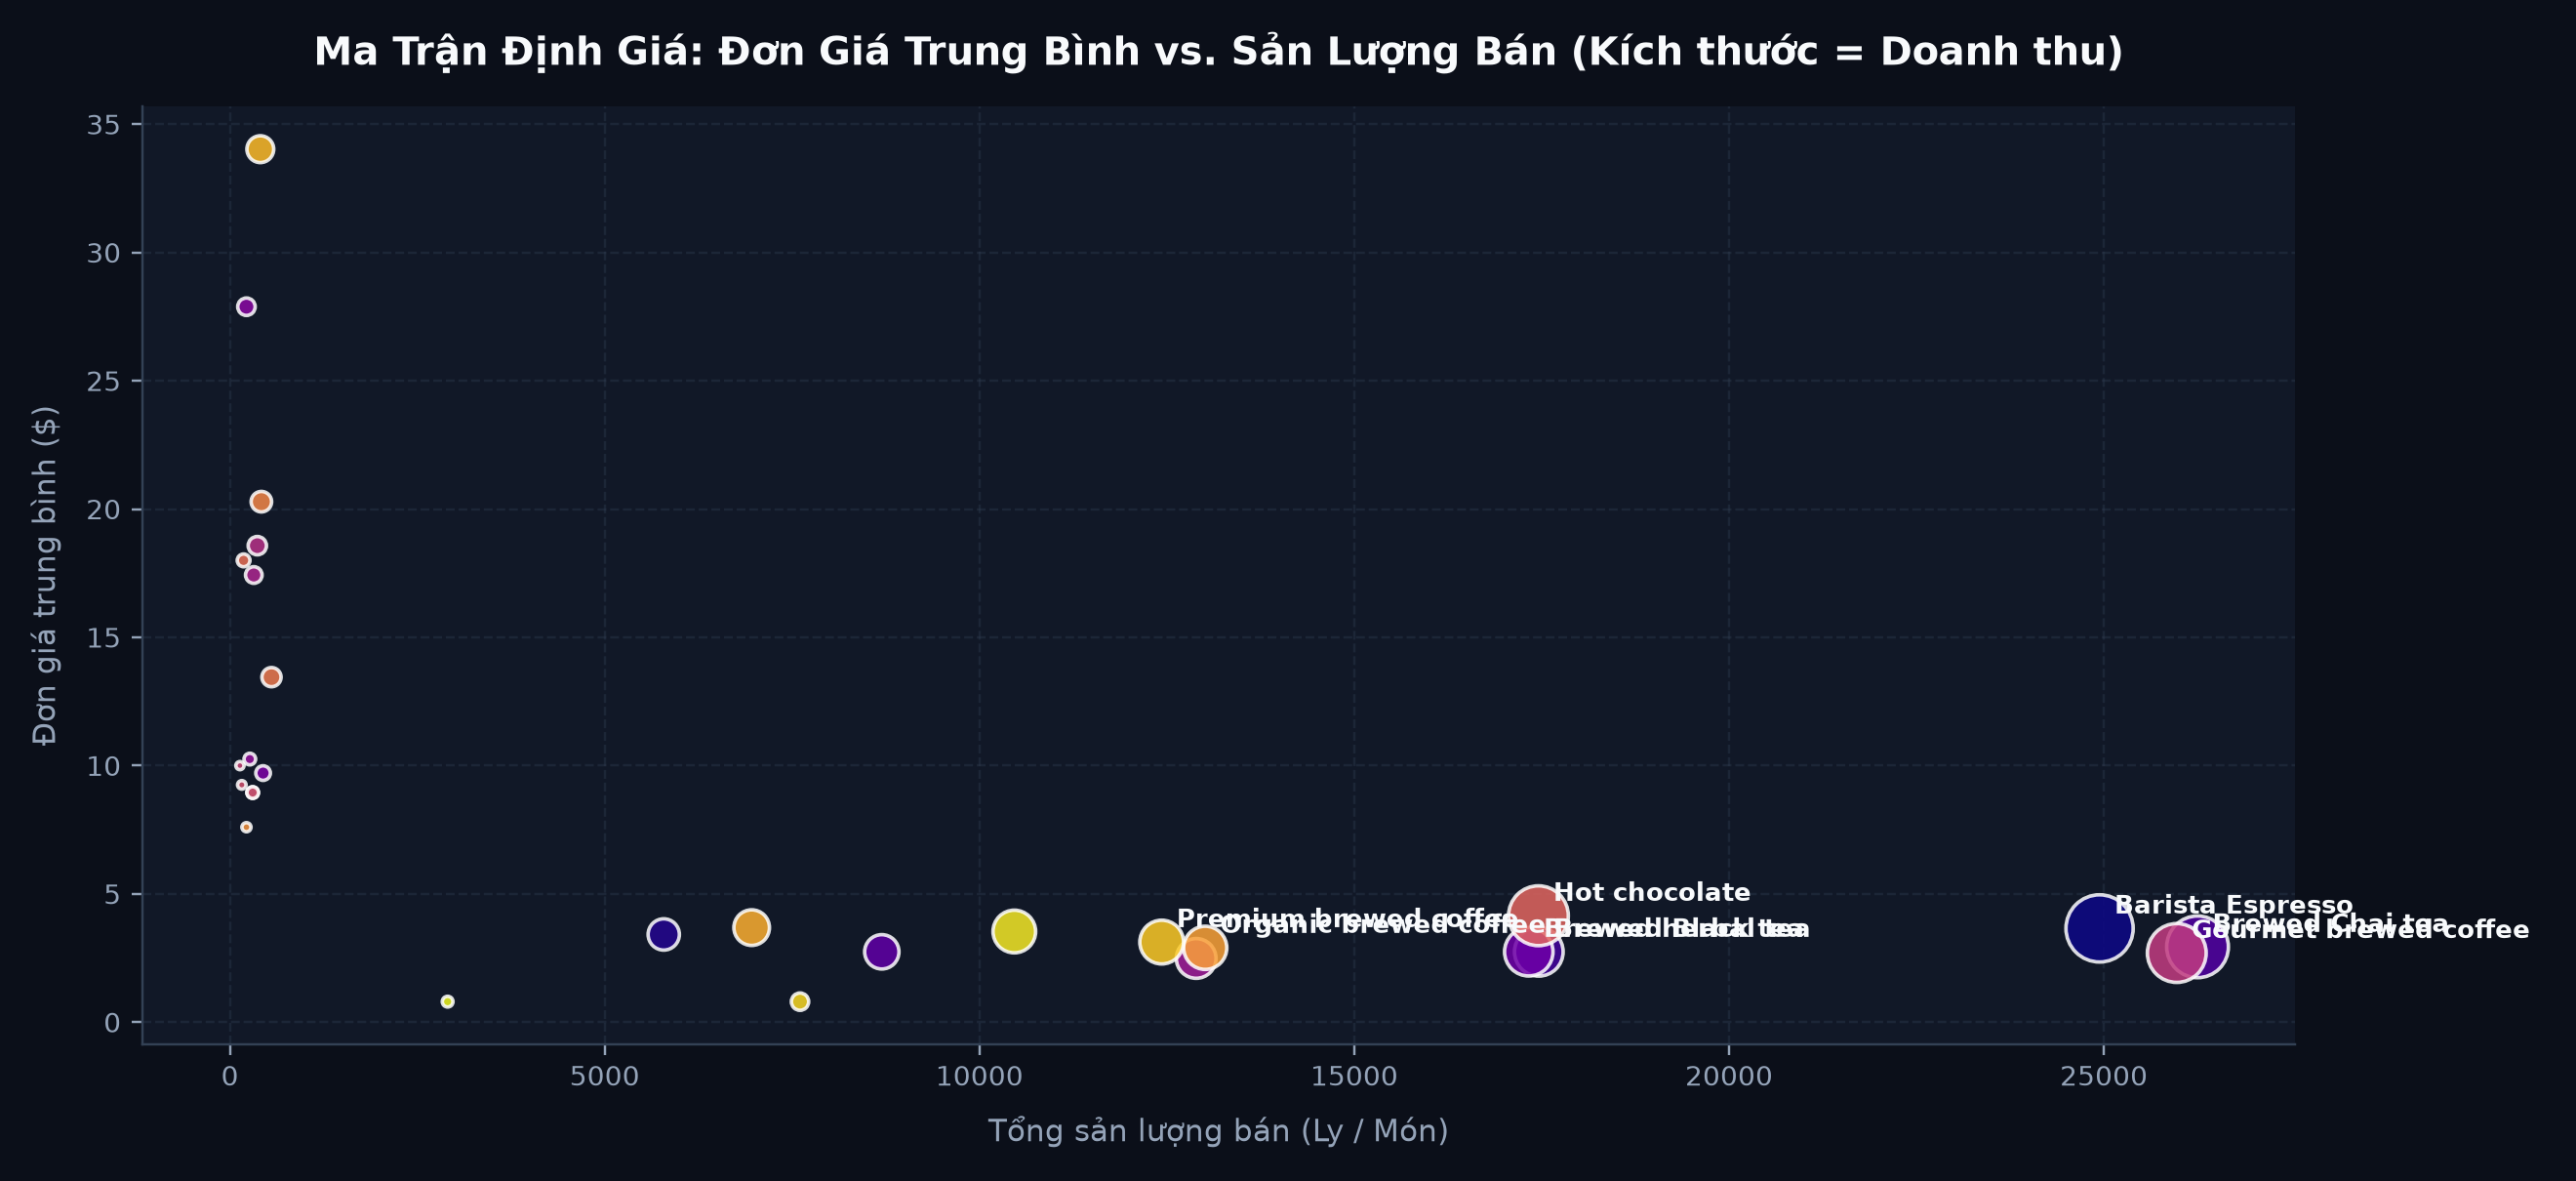

In [1]:
# Biểu đồ 19: Scatter Bubble Price vs Volume (docs/charts/slide24_price_vs_volume_scatter.png)
display(Image(filename=str(PROJECT_ROOT / "docs" / "charts" / "slide24_price_vs_volume_scatter.png")))

### Biểu đồ 20: Cơ cấu Danh mục Theo Chi nhánh, Theo Ca Kinh doanh & Ma trận Tương quan (Correlation Matrix)
- **Nhận xét:** Cơ cấu tiêu thụ đồng nhất trên cả 3 chi nhánh và 4 ca kinh doanh. Biến `unit_price` tương quan dương mạnh với `revenue` (r = 0.67), và `transaction_qty` tương quan với `revenue` (r = 0.36).

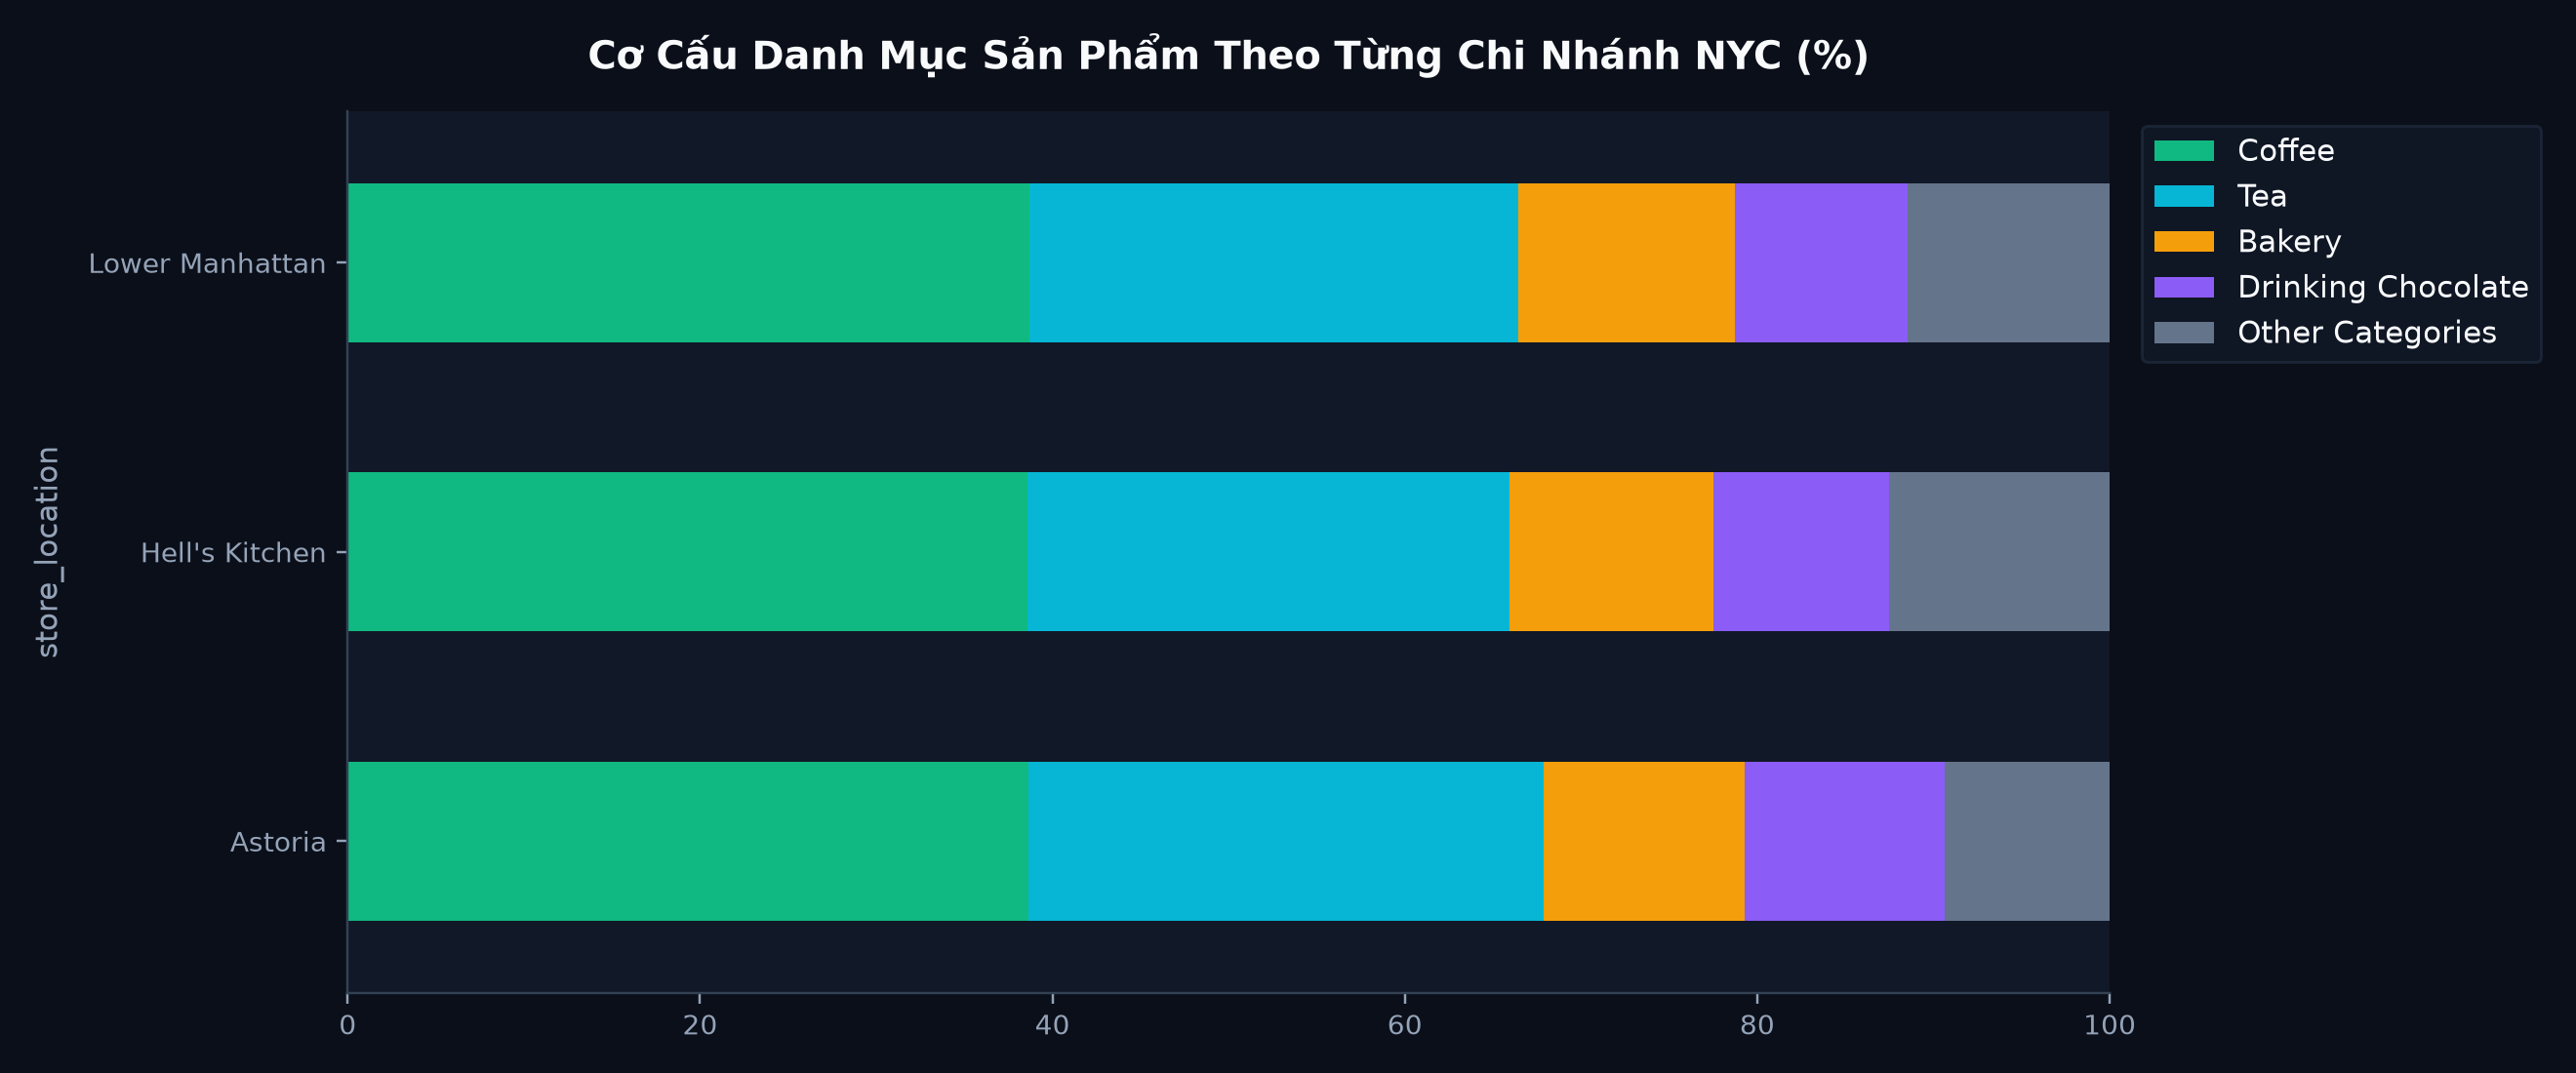

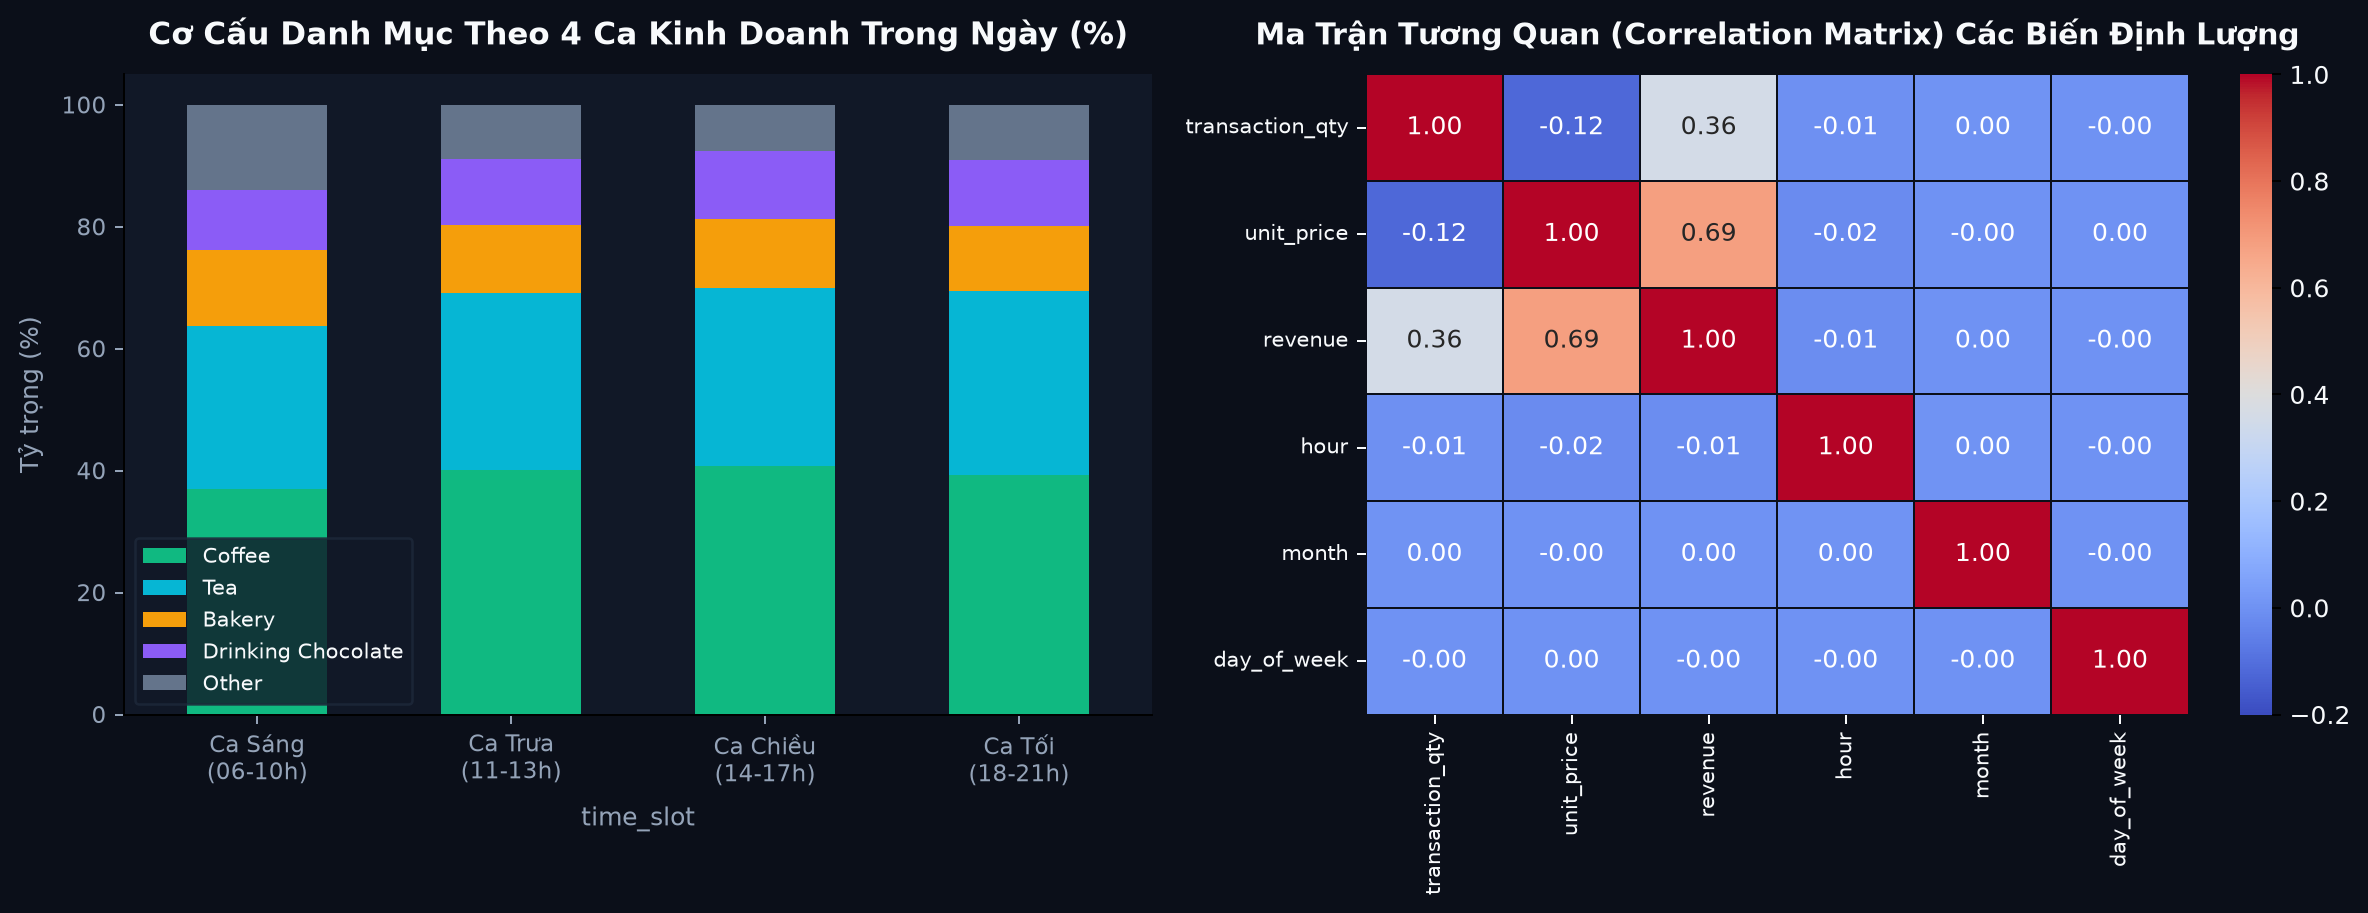

In [1]:
# Biểu đồ 20A & 20B: Cơ cấu danh mục theo chi nhánh, theo ca trực & Ma trận tương quan
display(Image(filename=str(PROJECT_ROOT / "docs" / "charts" / "slide25_category_by_store_and_slot.png")))
display(Image(filename=str(PROJECT_ROOT / "docs" / "charts" / "nb_chart20_timeslot_category_and_corr.png")))